# Phase 3: Exploratory data analysis

**CSE558 Data Science midterm project · Olist Brazilian e-commerce dataset**

**Research question.** Are late deliveries associated with lower customer review scores, and how does this relationship look when comparing orders with similar actual waiting times?

This notebook **describes** patterns in the final Phase 2 sample: tabular, time and text. It runs **no hypothesis tests**. It reports no p-values and makes no claims of significance or causation; those belong to Phase 4.

**Proportions are shown with 95% Wilson intervals.** The intervals show how precise each percentage is, so a rate from 40 orders is not read like a rate from 4,000. They are not tests.

**Inputs.** The notebook reads `outputs/phase2/analysis_table_final.parquet`, the final primary sample, and does not change it. **Outputs** go to `outputs/phase3/`: summary CSVs, and figures as PNG at 200 dpi.

**How to run.** Run notebooks 01 and 02 first, then *Kernel → Restart & Run All* here.

In [1]:
import os
from pathlib import Path
# All paths are relative to the project root. If Jupyter starts inside notebooks/, move up one level.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
import re
import json
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter, MultipleLocator
from IPython.display import Image, display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

P2 = Path("outputs") / "phase2"
OUT3 = Path("outputs") / "phase3"
FIG = OUT3 / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Colorblind-safe project palette: blue = on time/early, orange = late
C_ON, C_LATE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SCORE_RAMP = ["#d4cdf6", "#ada1ee", "#8676e2", "#6250d6", "#3b2d99"]   # review score 1 (light) -> 5 (dark), one hue

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 10, "axes.labelcolor": INK2, "axes.edgecolor": "#b9b8b2",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
})

def wilson(k, n, z=1.96):
    # 95% Wilson interval for a proportion k/n (descriptive precision, not a test)
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.where(n > 0, k / np.maximum(n, 1), np.nan)
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

FIGURES = []
def save(fig, name, title, shows, n_note, caveat):
    path = FIG / f"{name}.png"
    fig.savefig(path)
    plt.close(fig)
    FIGURES.append({"figure": name, "file": str(path), "title": title, "what_it_shows": shows,
                    "sample": n_note, "caveat": caveat})
    display(Image(filename=str(path)))

def summarise(scores):
    s = pd.Series(scores)
    return {"n": int(s.size), "mean": s.mean(), "median": s.median(), "sd": s.std(), "q1": s.quantile(0.25),
            "q3": s.quantile(0.75), "pct_low_1_2": 100 * (s <= 2).mean(), "pct_5": 100 * (s == 5).mean()}

LABEL = {0: "On time or early", 1: "Late"}

## 3A. Validate the analysis dataset before plotting

In [2]:
f = pd.read_parquet(P2 / "analysis_table_final.parquet")
audited = pd.read_parquet(P2 / "analysis_table_audited.parquet")
p2_summary = json.load(open(P2 / "p2_summary.json"))

DAY = 86400
D, E, P = f.order_delivered_customer_date, f.order_estimated_delivery_date, f.order_purchase_timestamp
checks = {
    "one row per order_id": f.order_id.is_unique,
    "rows = Phase 2 summary (95,296)": len(f) == p2_summary["final_rows"] == 95_296,
    "late orders = 6,353": int(f.is_late.sum()) == 6_353,
    "on time or early = 88,943": int((f.is_late == 0).sum()) == 88_943,
    "3 pre-purchase-review orders excluded (marked in audited table, absent here)":
        int(audited.excluded_from_primary.sum()) == 3 and not f.order_id.isin(audited.order_id[audited.excluded_from_primary == 1]).any(),
    "no review answered before purchase": not (f.review_answer_timestamp < P).any(),
    "is_late = delivery calendar date > estimated date": (f.is_late == (D.dt.normalize() > E)).all(),
    "delay_calendar_days = whole days between those dates": (f.delay_calendar_days == (D.dt.normalize() - E).dt.days).all(),
    "delay_days = (delivery - estimate) in days": np.allclose(f.delay_days, (D - E).dt.total_seconds() / DAY),
    "wait_days = (delivery - purchase) in days": np.allclose(f.wait_days, (D - P).dt.total_seconds() / DAY),
    "promised_days = (estimate - purchase) in days": np.allclose(f.promised_days, (E - P).dt.total_seconds() / DAY),
    "low_score = score 1 or 2": (f.low_score == (f.review_score <= 2)).all(),
    "has_comment = non-blank message": (f.has_comment == (f.review_comment_message.fillna("").str.strip() != "")).all(),
    "has_any_text = non-blank message or title": (f.has_any_text == ((f.review_comment_message.fillna("").str.strip() != "") |
                                                                     (f.review_comment_title.fillna("").str.strip() != ""))).all(),
    "review_before_delivery uses the ANSWER timestamp": (f.review_before_delivery == (f.review_answer_timestamp < D)).all(),
    "... and is NOT the survey-creation comparison": (f.review_before_delivery != (f.review_creation_date < D.dt.normalize())).any(),
    "survey created before or at the answer (never after)": (f.review_creation_date <= f.review_answer_timestamp).all(),
}
validation = pd.Series(checks, name="passed").to_frame()
validation.to_csv(OUT3 / "p3_validation.csv")
assert validation.passed.all(), validation[~validation.passed]

flags = ["review_before_delivery", "review_shared_across_orders", "flag_repeat_customer", "flag_wait_over_60",
         "flag_delay_over_30", "flag_promised_day_positive_delay", "flag_title_only", "flag_sparse_period_2016"]
print(f"Final sample: {len(f):,} orders | late {int(f.is_late.sum()):,} | on time or early {int((f.is_late == 0).sum()):,}")
print("Quality flags in the sample:", {c: int(f[c].sum()) for c in flags})
print("review_creation_date = when Olist sent the survey (a date); review_answer_timestamp = when the customer answered.")
validation

Final sample: 95,296 orders | late 6,353 | on time or early 88,943
Quality flags in the sample: {'review_before_delivery': 4624, 'review_shared_across_orders': 867, 'flag_repeat_customer': 5163, 'flag_wait_over_60': 290, 'flag_delay_over_30': 341, 'flag_promised_day_positive_delay': 1269, 'flag_title_only': 1701, 'flag_sparse_period_2016': 262}
review_creation_date = when Olist sent the survey (a date); review_answer_timestamp = when the customer answered.


,passed
one row per order_id,True
"rows = Phase 2 summary (95,296)",True
"late orders = 6,353",True
"on time or early = 88,943",True
"3 pre-purchase-review orders excluded (marked in audited table, absent here)",True
no review answered before purchase,True
is_late = delivery calendar date > estimated date,True
delay_calendar_days = whole days between those dates,True
delay_days = (delivery - estimate) in days,True
wait_days = (delivery - purchase) in days,True


**Validation summary.** The input dataset is the cleaned Phase 2 primary sample: 95,296 orders, one row each, with 6,353 late. The 3 pre-purchase-review orders are absent, and every key variable recomputes from its raw timestamps exactly as documented.

The review-timing flag is built from the customer's *answer* time. The survey's *creation* date is a different column, so the two definitions classify some orders differently.

---
## 3B. Tabular exploration

### 1. Review-score distribution

**Why a bar chart?** A review score is an **ordinal** label from 1 to 5. It is ranked, but the gap between 1 and 2 stars need not equal the gap between 4 and 5. A bar per score shows the whole distribution honestly. A mean is convenient but hides the shape: a mean of 4 can come from mostly 4s, or from many 5s plus some 1s.

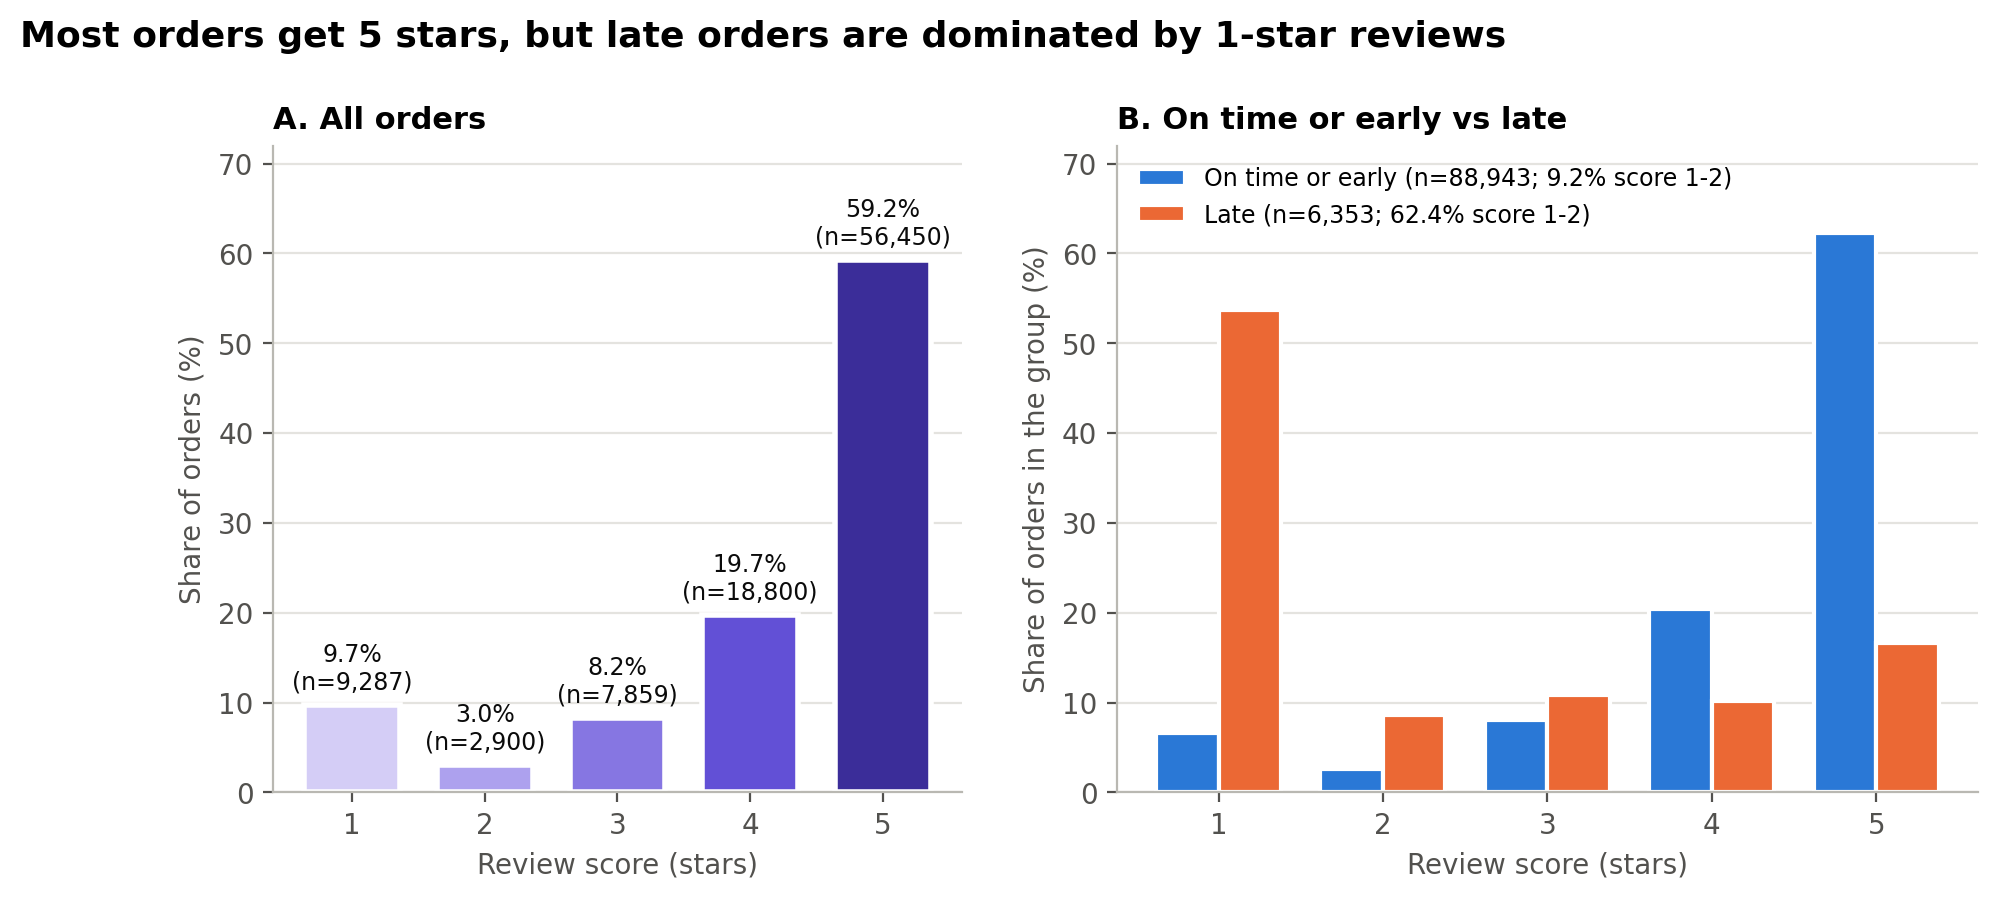

,group,n,mean,median,sd,q1,q3,pct_low_1_2,pct_5
0,All orders,95296,4.157,5.0,1.284,4.0,5.0,12.789,59.236
1,On time or early,88943,4.291,5.0,1.148,4.0,5.0,9.247,62.283
2,Late,6353,2.273,1.0,1.573,1.0,4.0,62.364,16.591


In [3]:
overall = summarise(f.review_score)
by_late = {k: summarise(g.review_score) for k, g in f.groupby("is_late")}
dist = (pd.crosstab(f.review_score, f.is_late, normalize="columns") * 100).rename(columns=LABEL)
counts = f.review_score.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.bar(counts.index, counts / len(f) * 100, color=SCORE_RAMP, edgecolor="white", linewidth=2, width=0.72)
for s, c in counts.items():
    ax.text(s, c / len(f) * 100 + 1.2, f"{c / len(f):.1%}\n(n={c:,})", ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set(xlabel="Review score (stars)", ylabel="Share of orders (%)", ylim=(0, 72), xticks=range(1, 6))
ax.set_title("A. All orders", fontsize=11)
ax.grid(axis="x", visible=False)

ax = axes[1]
w = 0.38
for i, (k, col) in enumerate([(0, C_ON), (1, C_LATE)]):
    ax.bar(np.arange(1, 6) + (i - 0.5) * w, dist[LABEL[k]], width=w, color=col, edgecolor="white", linewidth=1.5,
           label=f"{LABEL[k]} (n={by_late[k]['n']:,}; {by_late[k]['pct_low_1_2']:.1f}% score 1-2)")
ax.set(xlabel="Review score (stars)", ylabel="Share of orders in the group (%)", xticks=range(1, 6), ylim=(0, 72))
ax.set_title("B. On time or early vs late", fontsize=11)
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(axis="x", visible=False)
fig.suptitle("Most orders get 5 stars, but late orders are dominated by 1-star reviews", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.03)
save(fig, "F01_score_distribution", "Review-score distribution, overall and by lateness",
     "Share of orders at each star level; panel B compares on-time/early and late orders within each group",
     f"{len(f):,} orders ({by_late[0]['n']:,} on time or early, {by_late[1]['n']:,} late)",
     "Scores are ordinal; group shares are not adjusted for waiting time or review timing")

score_summary = pd.DataFrame([{"group": "All orders", **overall}] +
                             [{"group": LABEL[k], **v} for k, v in by_late.items()]).round(3)
score_summary

**Reading it.**

- **Panel A:** the distribution is very skewed. Most orders get 5 stars, and the 1-star bar is the next notable spike, so customers tend to answer at the extremes.
- **Panel B:** among late orders the picture flips. 1 star is the most common score and 5 stars is far less common.
- The groups are very different in size, 6,353 late against 88,943 on time or early. Each panel therefore shows shares *within* its group, not raw counts.

**What we cannot conclude:** that lateness *causes* the low scores. Late orders also wait longer, and many were reviewed before they arrived (section 3D).

### 2. Customer-state differences

**Why this plot?** It shows the late rate per state with an interval, sorted from highest to lowest. The order count is printed beside each state. Small states such as RR (41 orders) get wide intervals, so a high rate there is weak evidence of a real difference.

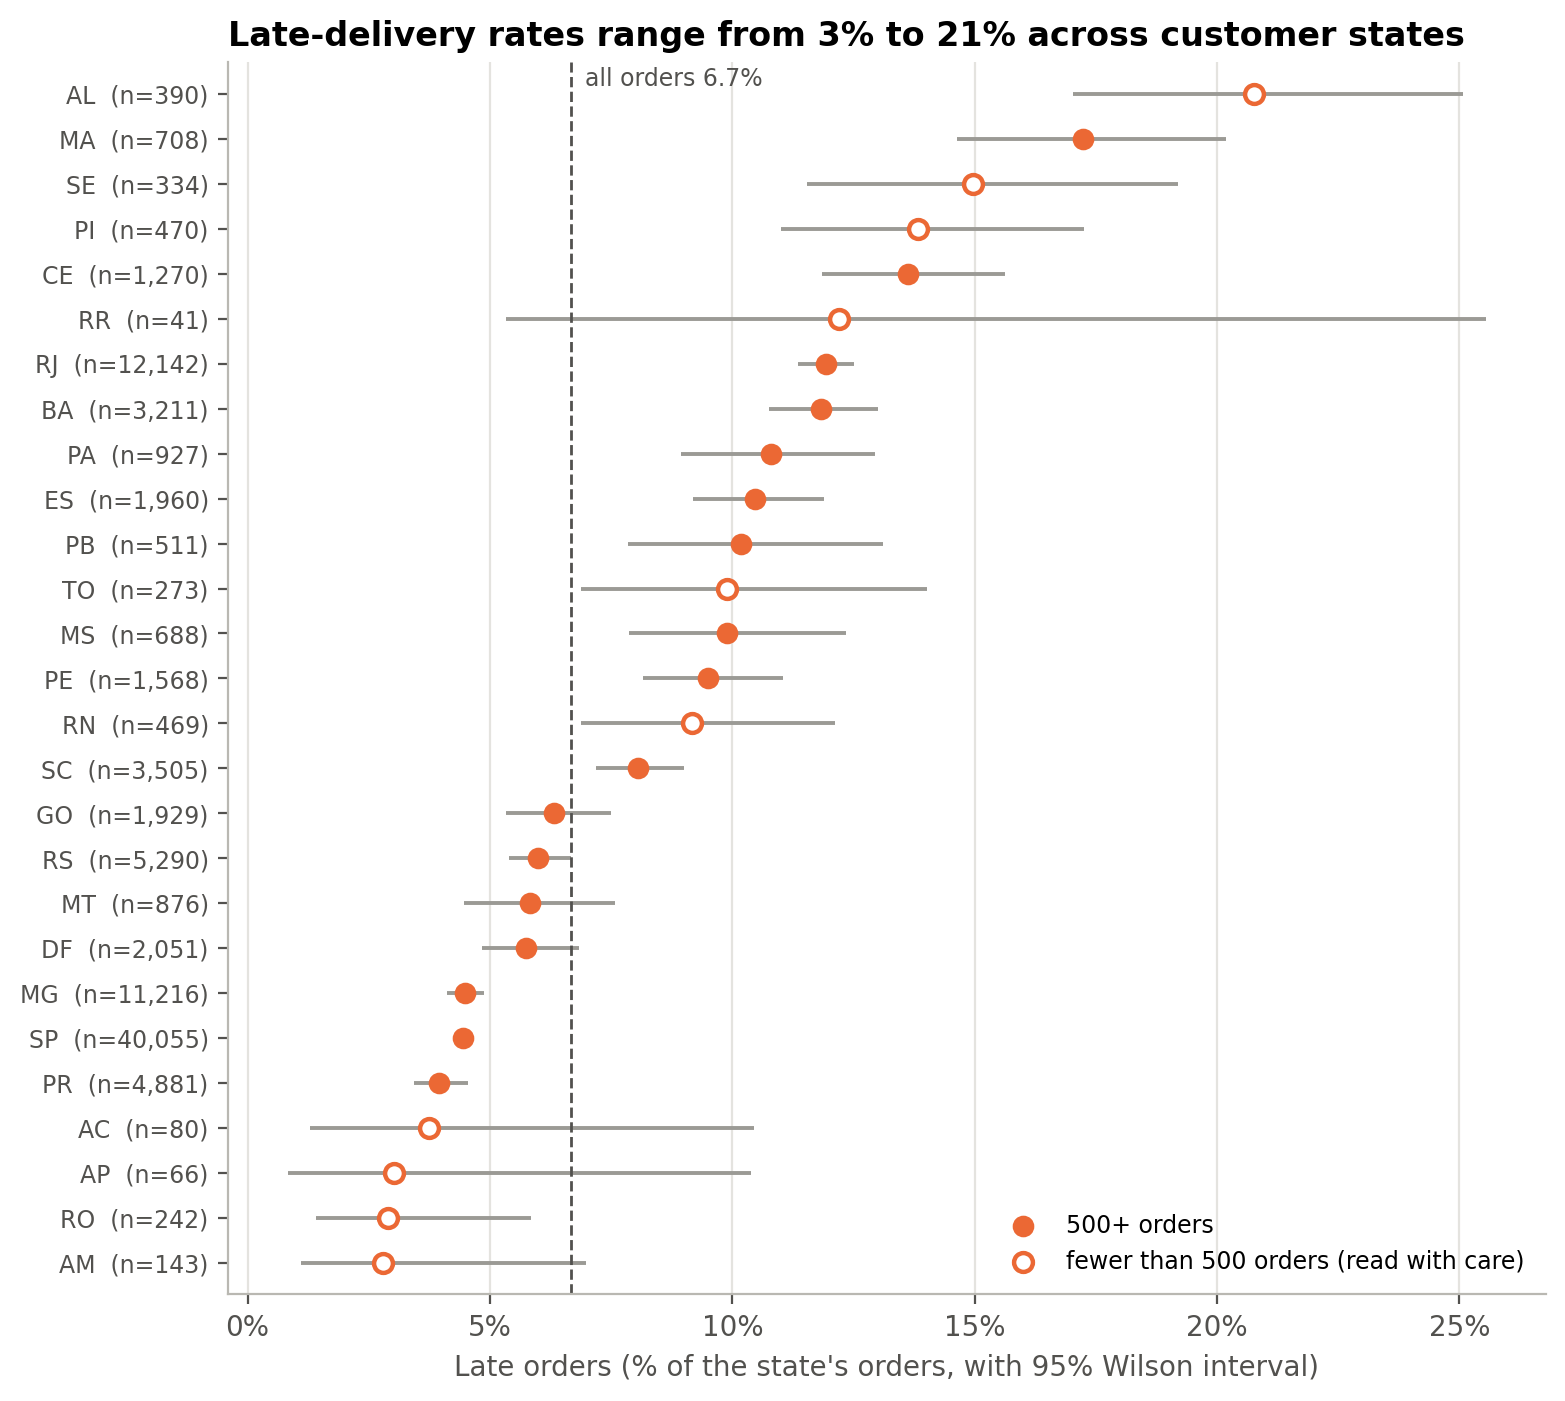

,customer_state,orders,late,mean_score,low,median_wait,late_pct,low_pct,late_ci_low,late_ci_high,small_sample_lt_500
1,AL,390,81,3.86,82,22.33,20.77,21.03,17.04,25.07,True
9,MA,708,122,3.83,142,19.16,17.23,20.06,14.63,20.19,False
24,SE,334,50,3.91,63,17.99,14.97,18.86,11.54,19.19,True
16,PI,470,65,3.99,76,16.29,13.83,16.17,11.00,17.25,True
5,CE,1270,173,3.95,217,18.19,13.62,17.09,11.84,15.62,False
21,RR,41,5,3.90,6,25.01,12.20,14.63,5.32,25.54,True
18,RJ,12142,1448,3.97,2221,12.01,11.93,18.29,11.36,12.51,False
4,BA,3211,380,3.93,546,16.85,11.83,17.00,10.76,13.00,False


In [4]:
st = f.groupby("customer_state").agg(orders=("order_id", "size"), late=("is_late", "sum"),
                                     mean_score=("review_score", "mean"), low=("low_score", "sum"),
                                     median_wait=("wait_days", "median")).reset_index()
st["late_pct"] = 100 * st.late / st.orders
st["low_pct"] = 100 * st.low / st.orders
lo, hi = wilson(st.late, st.orders)
st["late_ci_low"], st["late_ci_high"] = 100 * lo, 100 * hi
st["small_sample_lt_500"] = st.orders < 500
st = st.sort_values("late_pct")
overall_late = 100 * f.is_late.mean()

fig, ax = plt.subplots(figsize=(8.5, 8))
y = np.arange(len(st))
ax.errorbar(st.late_pct, y, xerr=[st.late_pct - st.late_ci_low, st.late_ci_high - st.late_pct], fmt="none",
            ecolor="#9b9a95", elinewidth=1.4, capsize=0)
big = ~st.small_sample_lt_500.values
ax.scatter(st.late_pct[big], y[big], s=46, color=C_LATE, zorder=3, label="500+ orders")
ax.scatter(st.late_pct[~big], y[~big], s=46, facecolor="white", edgecolor=C_LATE, linewidth=1.6, zorder=3,
           label="fewer than 500 orders (read with care)")
ax.axvline(overall_late, color=INK2, linestyle="--", linewidth=1)
ax.text(overall_late + 0.3, len(st) - 0.4, f"all orders {overall_late:.1f}%", fontsize=8.5, color=INK2, va="top")
ax.set_yticks(y, [f"{s}  (n={n:,})" for s, n in zip(st.customer_state, st.orders)], fontsize=8.5)
ax.set(xlabel="Late orders (% of the state's orders, with 95% Wilson interval)", ylim=(-0.7, len(st) - 0.3))
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8.5)
top = st.iloc[-1]
ax.set_title(f"Late-delivery rates range from {st.late_pct.min():.0f}% to {st.late_pct.max():.0f}% across customer states")
save(fig, "F02_late_rate_by_state", "Late-delivery rate by customer state",
     "Share of each state's orders delivered late, with 95% Wilson intervals and order counts",
     f"{len(f):,} orders in 27 states; 6 states have fewer than 500 orders",
     "Small states have wide intervals; state differs from seller location and distance, which are not shown")
st.sort_values("late_pct", ascending=False).round(2).head(8)

**Reading it.**

- Late rates run from about 3% to 21%.
- The highest are mostly **north-eastern** states: AL, MA, SE, PI, CE and BA, with RJ close behind.
- São Paulo (SP), with 40,055 orders and by far the largest, is among the lowest at about 4.5%.
- The very low rates in AM, RO, AP and AC come from small states with wide intervals.

Several states have fewer than 500 orders (hollow dots), so their exact ranks are unreliable. Read the plot as "north-eastern customers more often receive late deliveries", not as a league table. Distance from the mostly south-eastern sellers is a plausible but untested explanation.

### 3. Product-category differences

**Why only 22 categories?** An order can contain several categories, so each order is labelled by its `dominant_category`, the category with the largest share of item price (documented in Phase 2). Only categories with **at least 1,000 orders** are plotted; all 74 are in the CSV. Rankings of tiny categories are mostly noise.

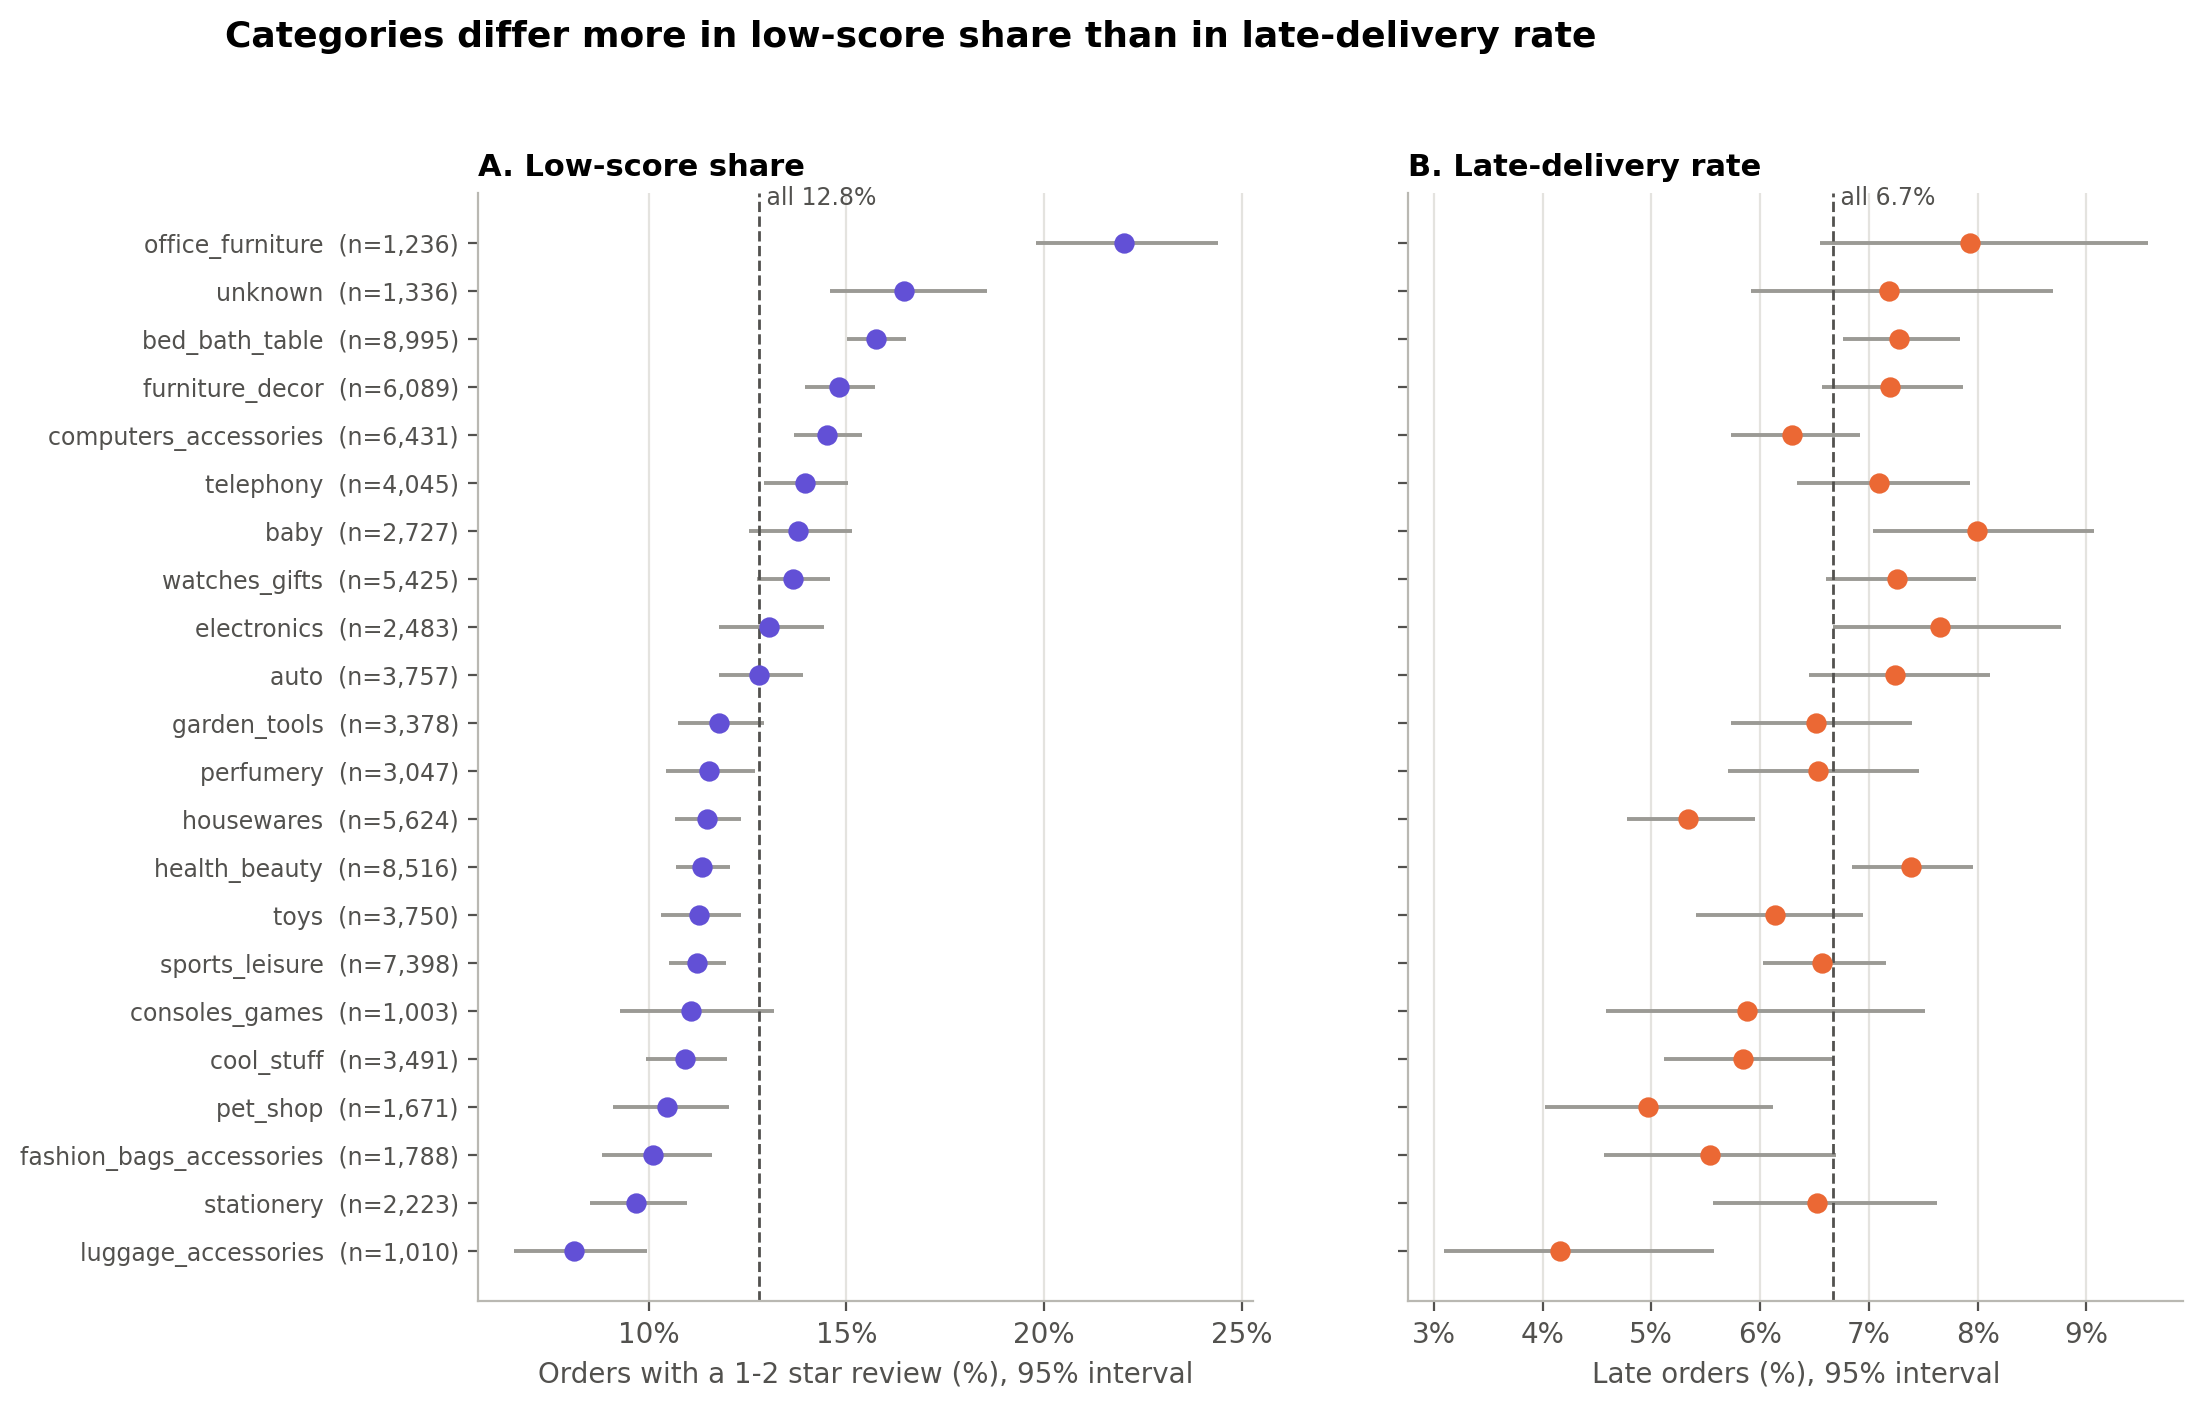

,dominant_category,orders,low_pct,late_pct,mean_score
57,office_furniture,1236,22.0,7.9,3.6
72,unknown,1336,16.5,7.2,4.0
7,bed_bath_table,8995,15.7,7.3,4.0
39,furniture_decor,6089,14.8,7.2,4.1
15,computers_accessories,6431,14.5,6.3,4.1
70,telephony,4045,13.9,7.1,4.1


In [5]:
cat = f.groupby("dominant_category").agg(orders=("order_id", "size"), late=("is_late", "sum"),
                                         low=("low_score", "sum"), mean_score=("review_score", "mean"),
                                         median_price=("items_price_total", "median")).reset_index()
cat["late_pct"], cat["low_pct"] = 100 * cat.late / cat.orders, 100 * cat.low / cat.orders
for k, col in [("late", "late"), ("low", "low")]:
    lo, hi = wilson(cat[col], cat.orders)
    cat[f"{k}_ci_low"], cat[f"{k}_ci_high"] = 100 * lo, 100 * hi
cat["included_in_figure_n_ge_1000"] = cat.orders >= 1000
big_cat = cat[cat.included_in_figure_n_ge_1000].sort_values("low_pct")

fig, axes = plt.subplots(1, 2, figsize=(11, 7.2), sharey=True)
y = np.arange(len(big_cat))
for ax, col, ci_l, ci_h, colr, xl, ref in [
        (axes[0], "low_pct", "low_ci_low", "low_ci_high", "#6250d6", "Orders with a 1-2 star review (%)", 100 * f.low_score.mean()),
        (axes[1], "late_pct", "late_ci_low", "late_ci_high", C_LATE, "Late orders (%)", overall_late)]:
    ax.errorbar(big_cat[col], y, xerr=[big_cat[col] - big_cat[ci_l], big_cat[ci_h] - big_cat[col]], fmt="none",
                ecolor="#9b9a95", elinewidth=1.4)
    ax.scatter(big_cat[col], y, s=40, color=colr, zorder=3)
    ax.axvline(ref, color=INK2, linestyle="--", linewidth=1)
    ax.text(ref, len(big_cat) - 0.2, f" all {ref:.1f}%", fontsize=8.5, color=INK2)
    ax.set_xlabel(xl + ", 95% interval")
    ax.xaxis.set_major_locator(MultipleLocator(5 if col == "low_pct" else 1))
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [f"{c}  (n={n:,})" for c, n in zip(big_cat.dominant_category, big_cat.orders)], fontsize=8.5)
axes[0].set_title("A. Low-score share", fontsize=11)
axes[1].set_title("B. Late-delivery rate", fontsize=11)
fig.suptitle("Categories differ more in low-score share than in late-delivery rate", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.0)
save(fig, "F03_categories", "Low-score share and late rate by dominant product category (n >= 1,000)",
     "For the 22 categories with at least 1,000 orders: share of 1-2 star reviews and share late, with 95% intervals",
     f"{int(big_cat.orders.sum()):,} of {len(f):,} orders; other categories in p3_state_category_summary.csv",
     "One label per order (price-dominant category); categories also differ in price, size and seller mix")
big_cat[["dominant_category", "orders", "low_pct", "late_pct", "mean_score"]].sort_values("low_pct", ascending=False).round(1).head(6)

**Reading it.** Among the large categories, the low-score share ranges from about 8% to 22%, while the late rate stays within about 4–8%.

`office_furniture` stands out: 22% low scores with an ordinary late rate of about 8%. So lateness is not the only thing that varies with low scores; product type (assembly, damage, expectations) plays a part too.

`unknown` (orders containing an uncategorised item) is shown like any other category, since it is a documented label rather than a missing value.

### 4. Order and freight characteristics

**Why binned summaries?** Price, freight and the freight ratio are extremely skewed: prices reach BRL 13,440. A scatter of 95,000 points against a 1–5 score is unreadable. Instead we sort orders into five equal-sized groups (**quintiles**) and plot the share of low scores in each, separately for late and on-time orders. Item and seller counts are grouped as 1, 2 or 3+, since most orders have one item from one seller. No value is trimmed.

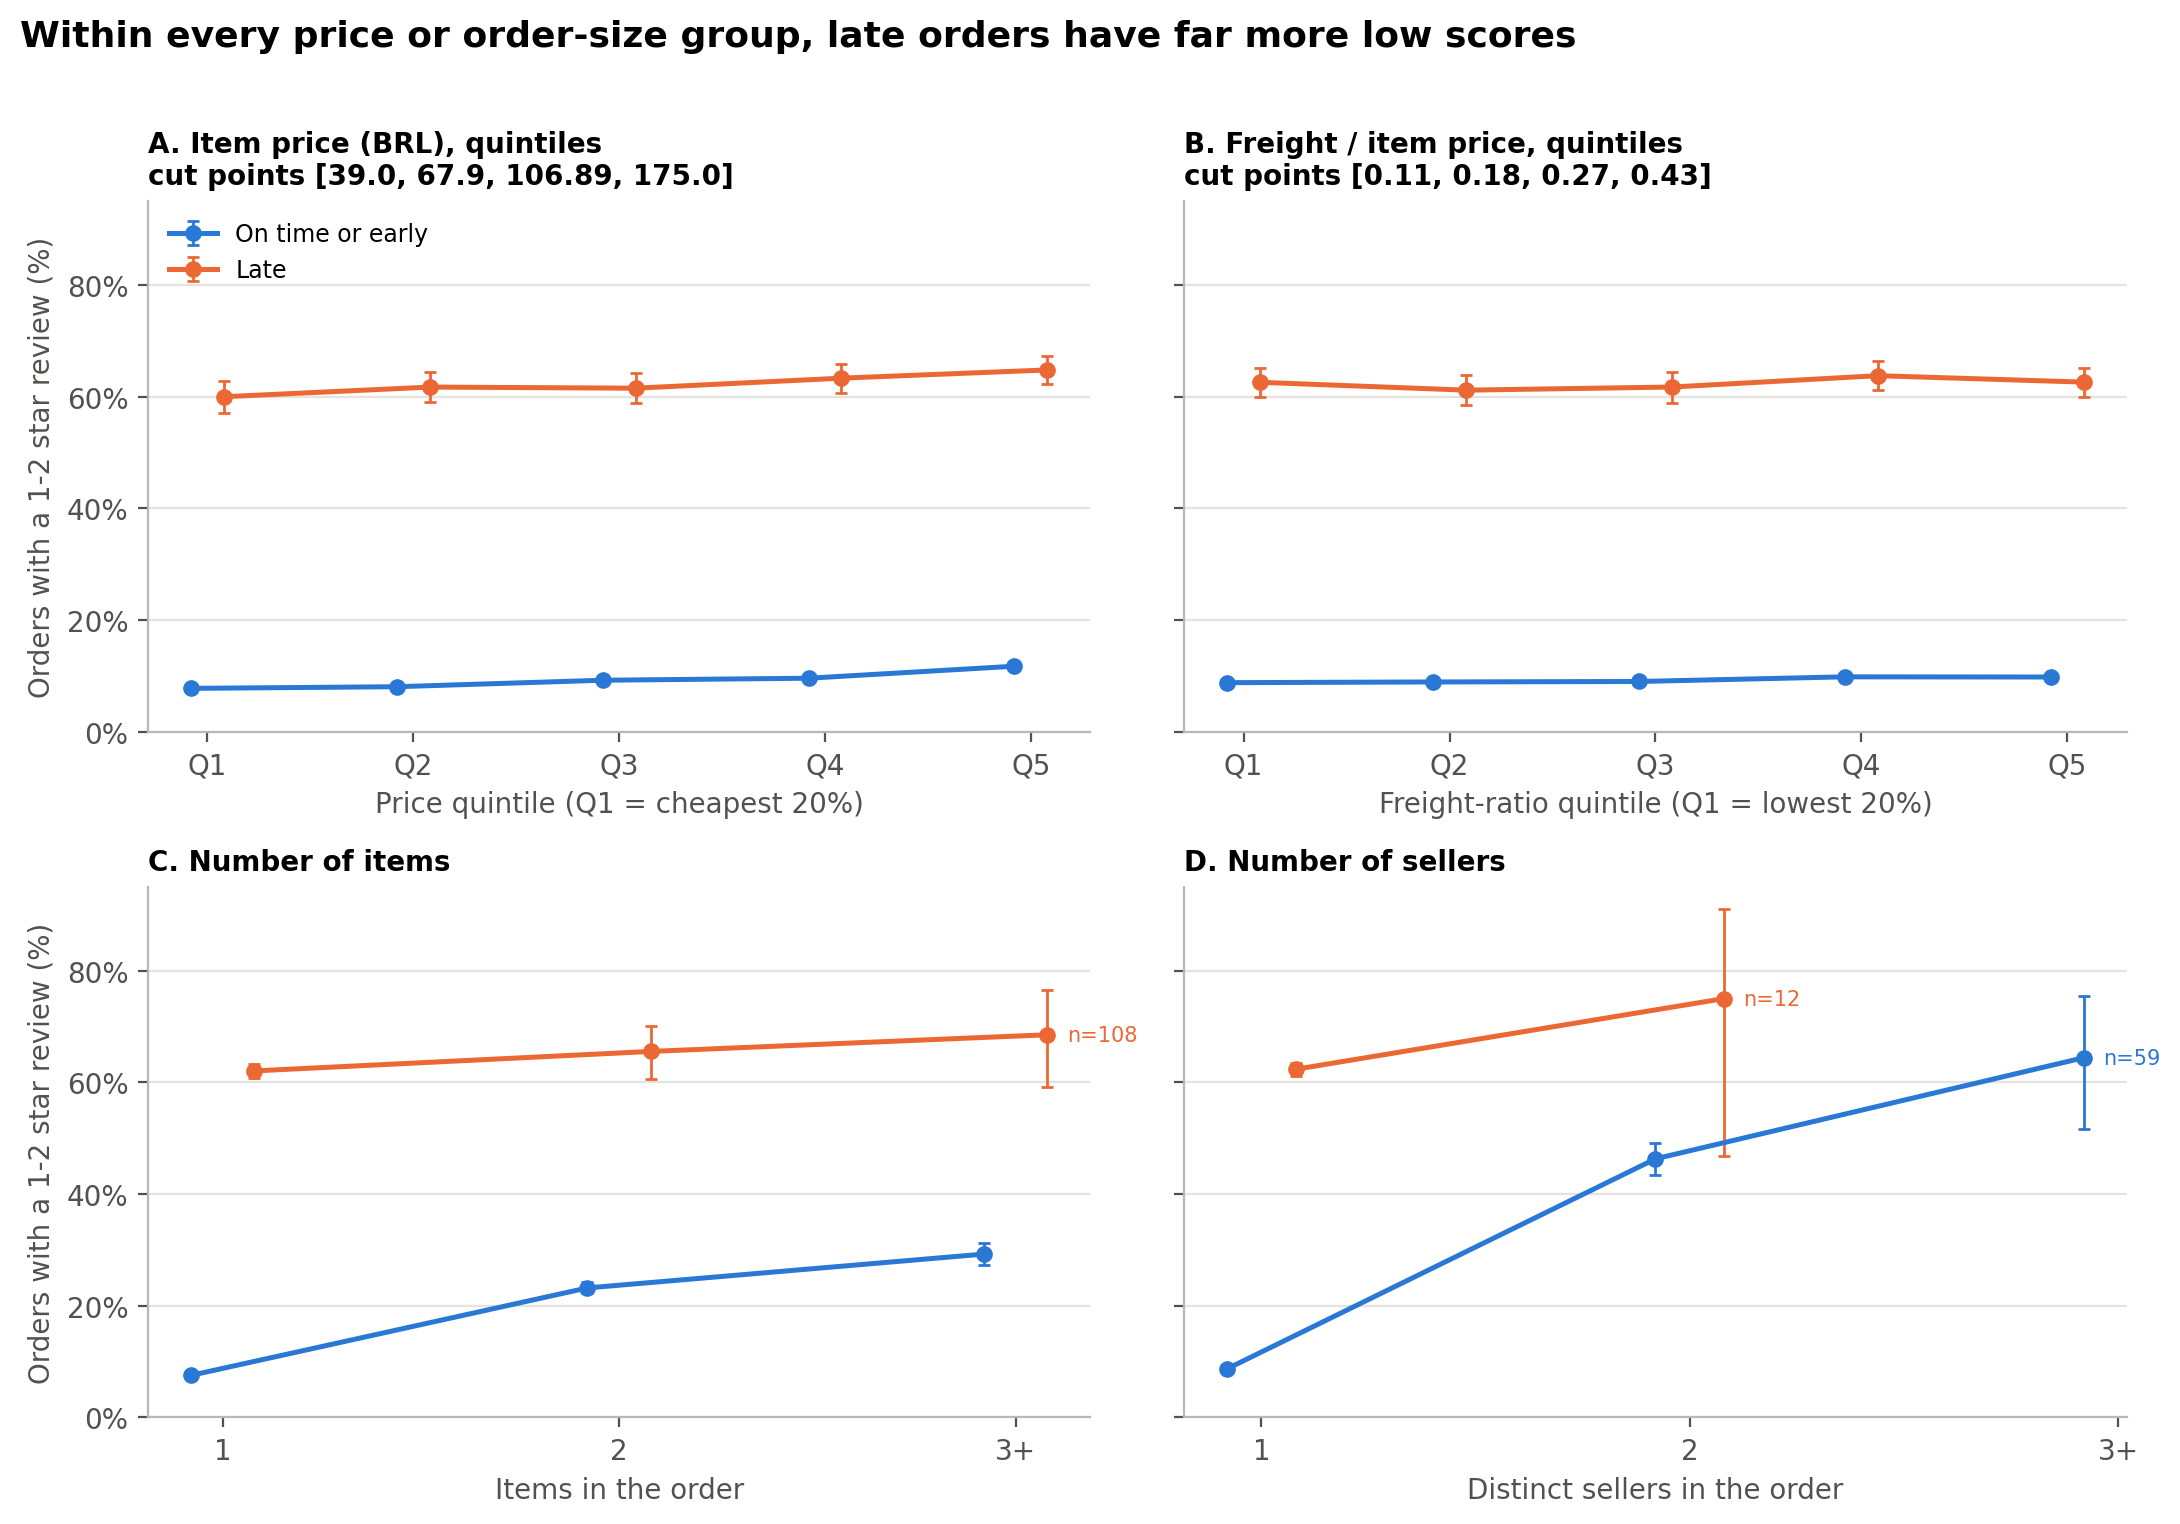

,variable,bin,group,orders,low_pct,ci_low,ci_high,mean_score,median_value
0,items_price_total,Q1,On time or early,18093,7.75,7.37,8.15,4.33,25.27
1,items_price_total,Q1,Late,1124,59.96,57.07,62.79,2.36,25.78
2,items_price_total,Q2,On time or early,17715,8.04,7.65,8.45,4.34,50.00
3,items_price_total,Q2,Late,1227,61.70,58.94,64.37,2.29,52.00
4,items_price_total,Q3,On time or early,17775,9.20,8.79,9.64,4.28,86.90
5,items_price_total,Q3,Late,1244,61.50,58.76,64.16,2.32,86.28
6,items_price_total,Q4,On time or early,17708,9.57,9.14,10.01,4.28,132.60
7,items_price_total,Q4,Late,1373,63.29,60.71,65.80,2.24,135.00
8,items_price_total,Q5,On time or early,17652,11.72,11.25,12.20,4.21,269.00
9,items_price_total,Q5,Late,1385,64.77,62.21,67.24,2.18,284.90


In [6]:
def binned(df, col, bins, labels):
    out = []
    cut = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True) if bins is not None else df[col]
    for (b, late), g in df.groupby([cut, "is_late"], observed=True):
        lo, hi = wilson(g.low_score.sum(), len(g))
        out.append({"variable": col, "bin": str(b), "group": LABEL[late], "orders": len(g),
                    "low_pct": 100 * g.low_score.mean(), "ci_low": 100 * float(lo), "ci_high": 100 * float(hi),
                    "mean_score": g.review_score.mean(), "median_value": g[col].median() if pd.api.types.is_numeric_dtype(g[col]) else np.nan})
    return pd.DataFrame(out)

def qbins(col):
    edges = f[col].quantile([0, .2, .4, .6, .8, 1]).to_numpy(copy=True)
    edges[0], edges[-1] = -np.inf, np.inf
    labels = [f"Q{i}" for i in range(1, 6)]
    return edges, labels

f["n_items_band"] = np.where(f.n_items >= 3, "3+", f.n_items.astype(str))
f["n_sellers_band"] = np.where(f.n_sellers >= 3, "3+", f.n_sellers.astype(str))
pieces = []
for col in ["items_price_total", "freight_ratio"]:
    e, l = qbins(col)
    pieces.append(binned(f, col, e, l))
pieces.append(binned(f, "n_items_band", None, None))
pieces.append(binned(f, "n_sellers_band", None, None))
order_bins = pd.concat(pieces, ignore_index=True)
q_edges = {col: f[col].quantile([.2, .4, .6, .8]).round(2).tolist() for col in ["items_price_total", "freight_ratio"]}

titles = {"items_price_total": f"A. Item price (BRL), quintiles\ncut points {q_edges['items_price_total']}",
          "freight_ratio": f"B. Freight / item price, quintiles\ncut points {q_edges['freight_ratio']}",
          "n_items_band": "C. Number of items", "n_sellers_band": "D. Number of sellers"}
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharey=True)
for ax, (var, ttl) in zip(axes.flat, titles.items()):
    d = order_bins[order_bins.variable == var]
    xs = list(dict.fromkeys(d.bin))
    for k, colr, off in [(0, C_ON, -0.08), (1, C_LATE, 0.08)]:
        g = d[d.group == LABEL[k]].set_index("bin").reindex(xs)
        x = np.arange(len(xs)) + off
        ax.errorbar(x, g.low_pct, yerr=[g.low_pct - g.ci_low, g.ci_high - g.low_pct], fmt="o-", color=colr,
                    ms=5, lw=1.8, elinewidth=1, capsize=2, label=LABEL[k])
        for xi, (n, v) in enumerate(zip(g.orders, g.low_pct)):
            if not np.isnan(v) and n < 300:
                ax.annotate(f"n={int(n)}", (xi + off, v), xytext=(7, 0), textcoords="offset points",
                            fontsize=7.5, color=colr, ha="left", va="center")
    ax.set_xticks(range(len(xs)), xs)
    ax.set_ylim(0, 95)
    ax.set_xlabel({"items_price_total": "Price quintile (Q1 = cheapest 20%)", "freight_ratio": "Freight-ratio quintile (Q1 = lowest 20%)",
                   "n_items_band": "Items in the order", "n_sellers_band": "Distinct sellers in the order"}[var])
    ax.set_title(ttl, fontsize=10)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
axes[0, 0].set_ylabel("Orders with a 1-2 star review (%)")
axes[1, 0].set_ylabel("Orders with a 1-2 star review (%)")
axes[0, 0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Within every price or order-size group, late orders have far more low scores", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.01)
fig.tight_layout()
save(fig, "F04_order_characteristics", "Low-score share by price, freight ratio, items and sellers, split by lateness",
     "Share of 1-2 star reviews within quintiles of price and freight ratio and within item/seller counts, late vs on time",
     f"{len(f):,} orders; groups with fewer than 300 orders are labelled with n",
     "Descriptive only; groups overlap with category and distance; multi-seller orders are rare")
order_bins.round(2).head(10)

**Reading it.**

- In every group, late orders have roughly 60% low scores against about 8–12% for on-time orders. Price and the freight ratio barely change that picture.
- Order size matters on its own. Even when delivered on time, two-item orders get 23% low scores (one-item orders 7.5%), and two-seller orders 46%. A plausible reason, untested here, is that such orders arrive in several parcels.
- Very few late orders have several sellers: 12 orders with two sellers, so treat that point as anecdotal.

These lines are descriptive, and small groups carry wide intervals.

---
## 3C. Time-related exploration

### 1. Monthly order volume, late rate and low-score share

**Why three stacked panels instead of one chart with two y-axes?** Order counts (thousands) and percentages live on different scales. A dual axis lets the reader's eye be steered by an arbitrary choice of scales, so we give each measure its own panel on a shared time axis.

The main trend starts in **January 2017**. 2016 has only 262 orders spread over three months (September, October and December, with November missing), so its monthly rates would be unstable. It is kept in the CSV.

Monthly late % vs low-score % (Jan 2017 - Aug 2018, 20 months): correlation 0.93


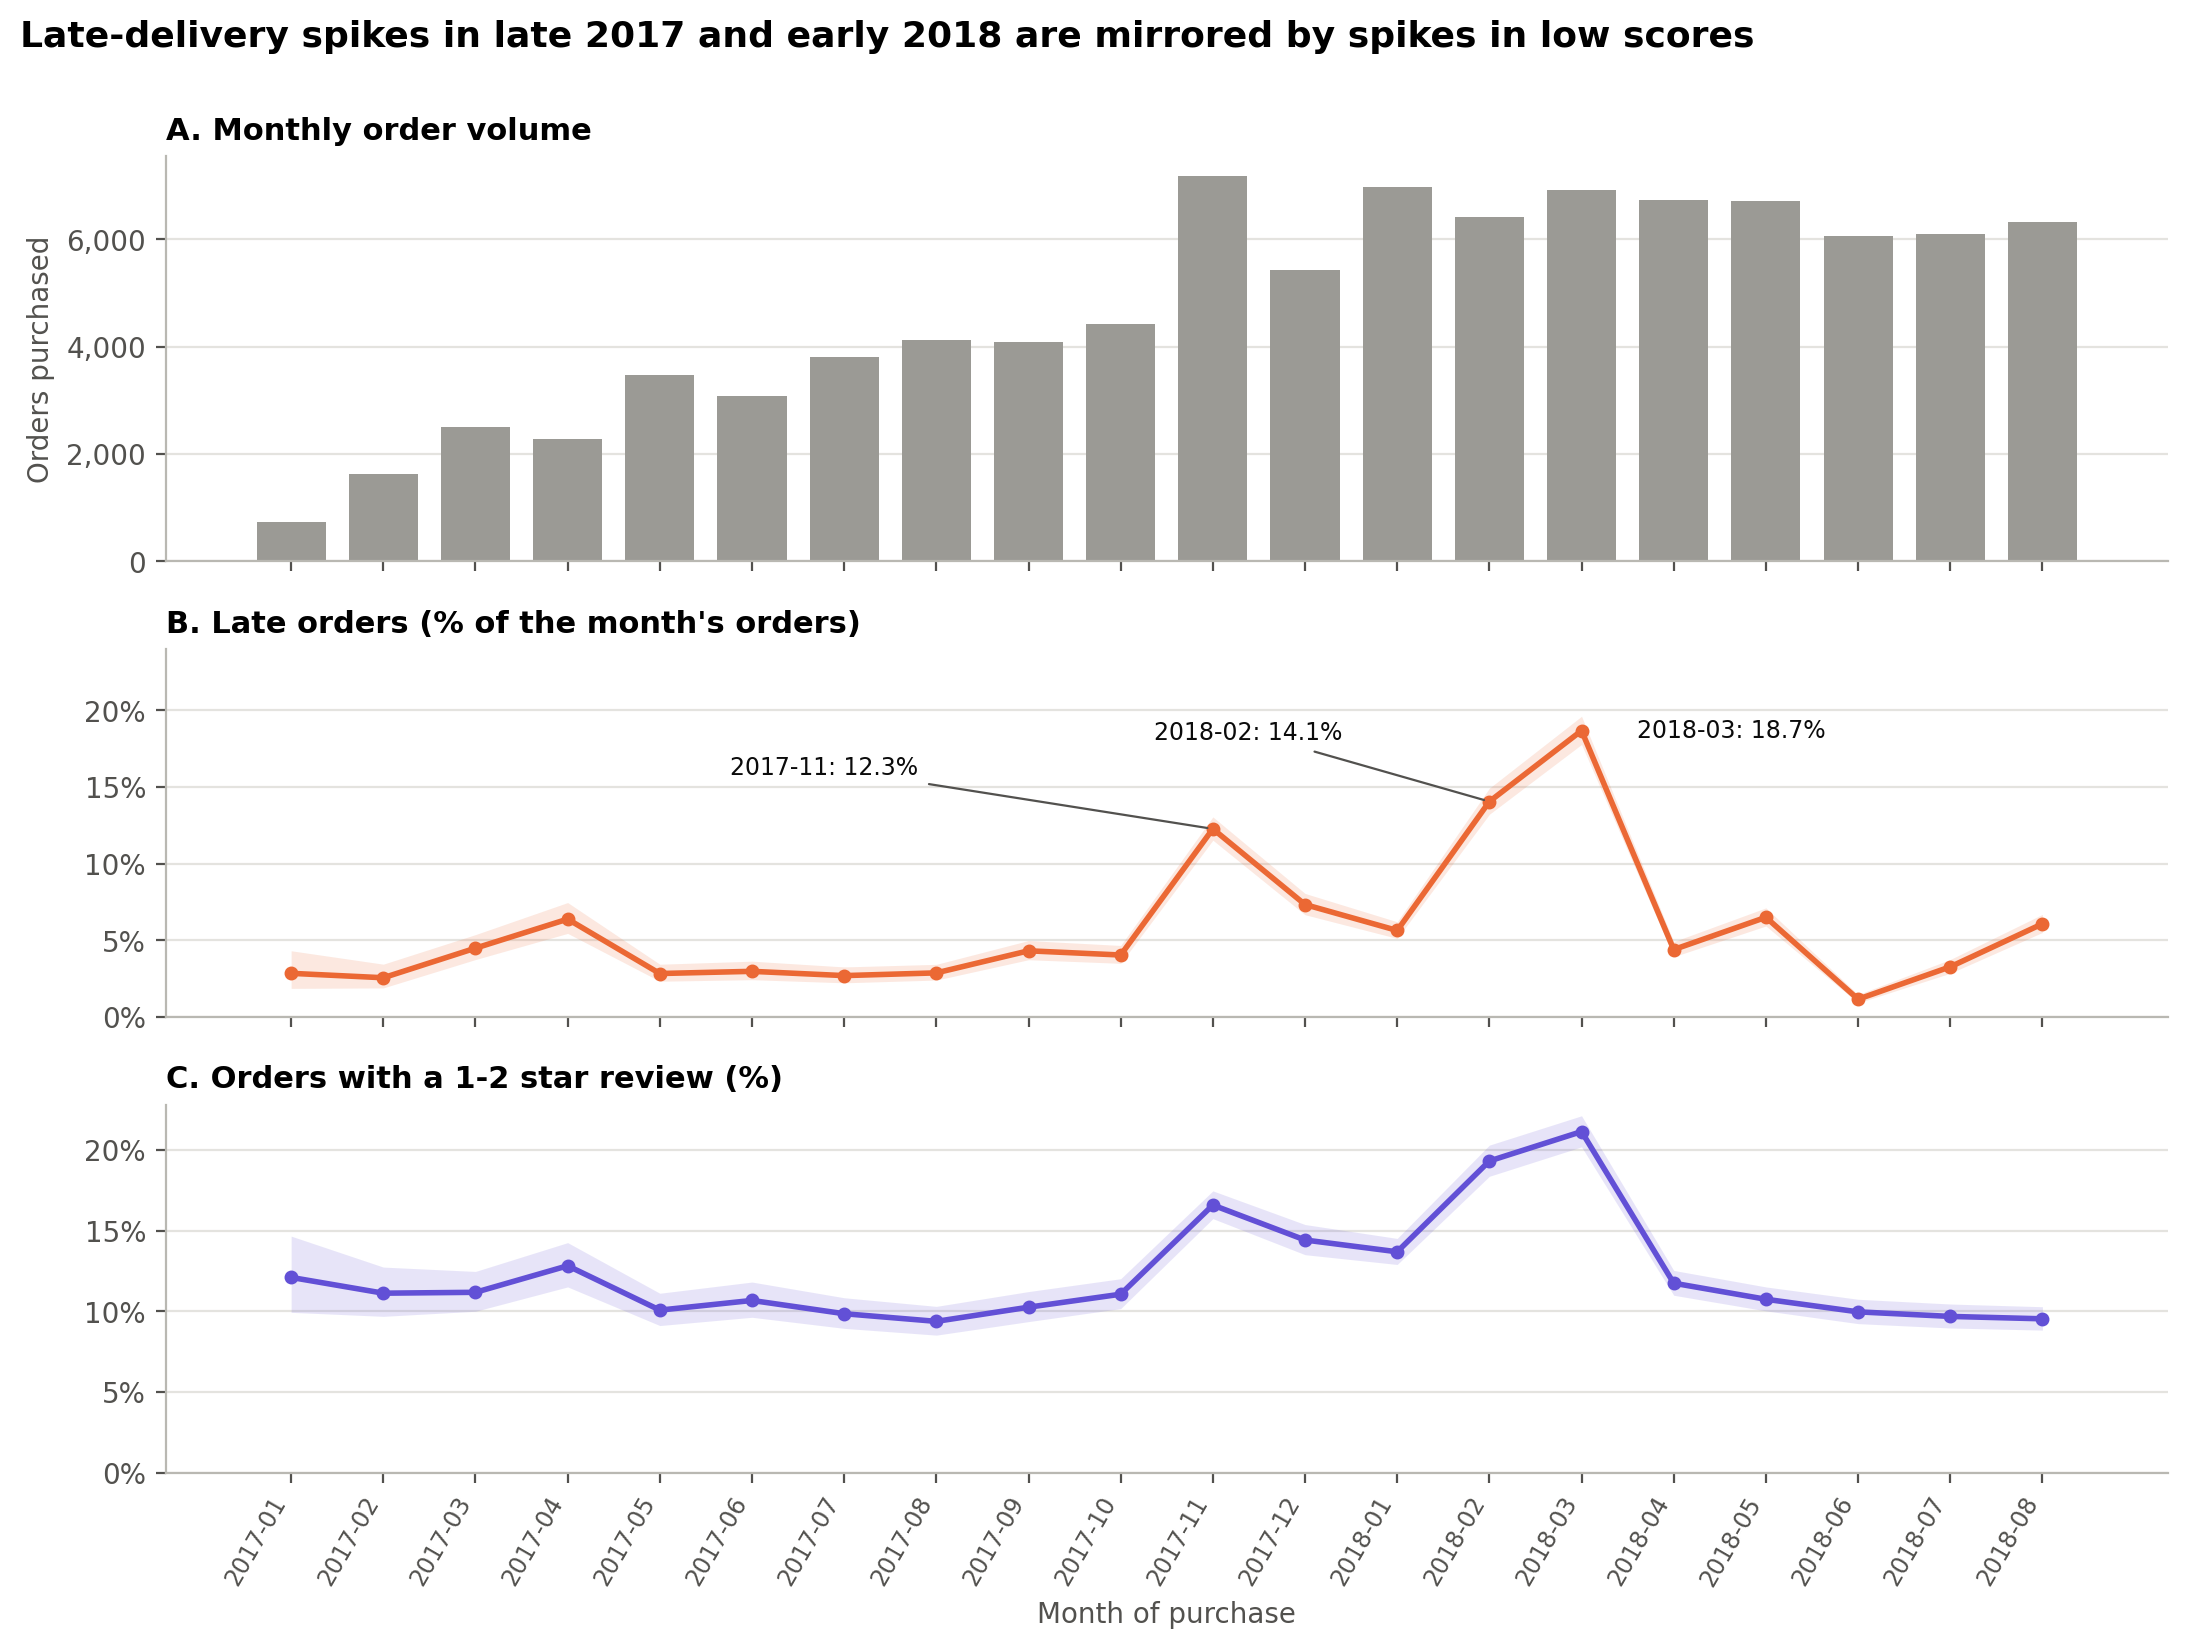

,purchase_yearmonth,orders,late,low,mean_score,median_wait_days,median_promised_days,late_pct,low_pct,late_ci_low,late_ci_high,low_ci_low,low_ci_high,in_main_trend
0,2016-09,1,1,1,1.00,54.81,18.49,100.00,100.00,20.65,100.00,20.65,100.00,False
1,2016-10,260,2,43,4.00,17.88,54.15,0.77,16.54,0.21,2.76,12.52,21.54,False
2,2016-12,1,0,0,5.00,4.69,26.03,0.00,0.00,0.00,79.35,0.00,79.35,False
3,2017-01,735,21,89,4.19,10.71,38.92,2.86,12.11,1.88,4.33,9.95,14.67,True
4,2017-02,1635,42,182,4.20,10.96,30.17,2.57,11.13,1.91,3.45,9.70,12.75,True
5,2017-03,2512,113,281,4.19,10.12,22.59,4.50,11.19,3.75,5.38,10.01,12.48,True
6,2017-04,2284,146,293,4.14,12.74,25.46,6.39,12.83,5.46,7.47,11.52,14.26,True
7,2017-05,3481,99,351,4.24,9.78,23.31,2.84,10.08,2.34,3.45,9.13,11.13,True
8,2017-06,3080,92,329,4.22,10.80,23.42,2.99,10.68,2.44,3.65,9.64,11.82,True
9,2017-07,3803,103,375,4.26,10.16,23.02,2.71,9.86,2.24,3.27,8.95,10.85,True


In [7]:
m = f.groupby("purchase_yearmonth").agg(orders=("order_id", "size"), late=("is_late", "sum"),
                                         low=("low_score", "sum"), mean_score=("review_score", "mean"),
                                         median_wait_days=("wait_days", "median"),
                                         median_promised_days=("promised_days", "median")).reset_index()
m["late_pct"], m["low_pct"] = 100 * m.late / m.orders, 100 * m.low / m.orders
lo, hi = wilson(m.late, m.orders); m["late_ci_low"], m["late_ci_high"] = 100 * lo, 100 * hi
lo, hi = wilson(m.low, m.orders); m["low_ci_low"], m["low_ci_high"] = 100 * lo, 100 * hi
m["in_main_trend"] = m.purchase_yearmonth >= "2017-01"
assert m.orders.sum() == len(f), "monthly totals do not reconcile with the sample"
mm = m[m.in_main_trend].reset_index(drop=True)
x = np.arange(len(mm))
corr_late_low = float(mm.late_pct.corr(mm.low_pct))   # Pearson correlation of the two monthly series (descriptive)
print(f"Monthly late % vs low-score % (Jan 2017 - Aug 2018, {len(mm)} months): correlation {corr_late_low:.2f}")

fig, axes = plt.subplots(3, 1, figsize=(11, 8.2), sharex=True, gridspec_kw={"height_ratios": [1.1, 1, 1]})
axes[0].bar(x, mm.orders, color="#9b9a95", width=0.75)
axes[0].set_ylabel("Orders purchased")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].set_title("A. Monthly order volume", fontsize=11)
for ax, col, colr, ttl in [(axes[1], "late", C_LATE, "B. Late orders (% of the month's orders)"),
                           (axes[2], "low", "#6250d6", "C. Orders with a 1-2 star review (%)")]:
    ax.fill_between(x, mm[f"{col}_ci_low"], mm[f"{col}_ci_high"], color=colr, alpha=0.15, linewidth=0)
    ax.plot(x, mm[f"{col}_pct"], color=colr, marker="o", ms=4, lw=2)
    ax.set_title(ttl, fontsize=11)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_ylim(0, None)
# label the three peaks in the empty space above the line, with thin leader lines
for ym, dx, dy, ha in [("2017-11", -3.2, 4.0, "right"), ("2018-02", -1.6, 4.5, "right"), ("2018-03", 0.6, 0.0, "left")]:
    r = mm[mm.purchase_yearmonth == ym].iloc[0]
    i = int(np.where(mm.purchase_yearmonth == ym)[0][0])
    axes[1].annotate(f"{ym}: {r.late_pct:.1f}%", (i, r.late_pct), xytext=(i + dx, r.late_pct + dy), textcoords="data",
                     fontsize=8.5, color=INK, ha=ha, va="center",
                     arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8) if ha == "right" else None)
axes[1].set_ylim(0, 24)
axes[2].set_xticks(x, mm.purchase_yearmonth, rotation=60, ha="right", fontsize=8.5)
axes[2].set_xlabel("Month of purchase")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.suptitle("Late-delivery spikes in late 2017 and early 2018 are mirrored by spikes in low scores",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "F05_monthly_trends", "Monthly order volume, late rate and low-score share (Jan 2017 - Aug 2018)",
     "Orders per purchase month; late share and 1-2 star share with 95% Wilson bands",
     f"{int(mm.orders.sum()):,} orders from Jan 2017; 2016 ({int(m[~m.in_main_trend].orders.sum())} orders) in the CSV only",
     "Months group by purchase date; a busy month (e.g. Black Friday, Nov 2017) may delay deliveries in the next month")
m.round(2)

**Reading it.** Months with a higher late rate tend to also have a higher share of low scores. The two curves move together, which fits the research question, but a shared trend over time can also come from other things changing at once, such as volume, carriers or seasons.

The November 2017 volume spike most likely reflects Black Friday promotions. It is followed by the highest late rates in November 2017 and February–March 2018.

### 2. Delivery durations and delays

**Why these plots?** Waiting and promised times are positive and right-skewed: most orders take 1–3 weeks, and a few take months. A **log-scaled x-axis** spreads out the bulk while keeping the tail visible, without deleting anything.

The delay is centred well below zero: Olist's estimates are usually generous. Dashed lines mark the medians.

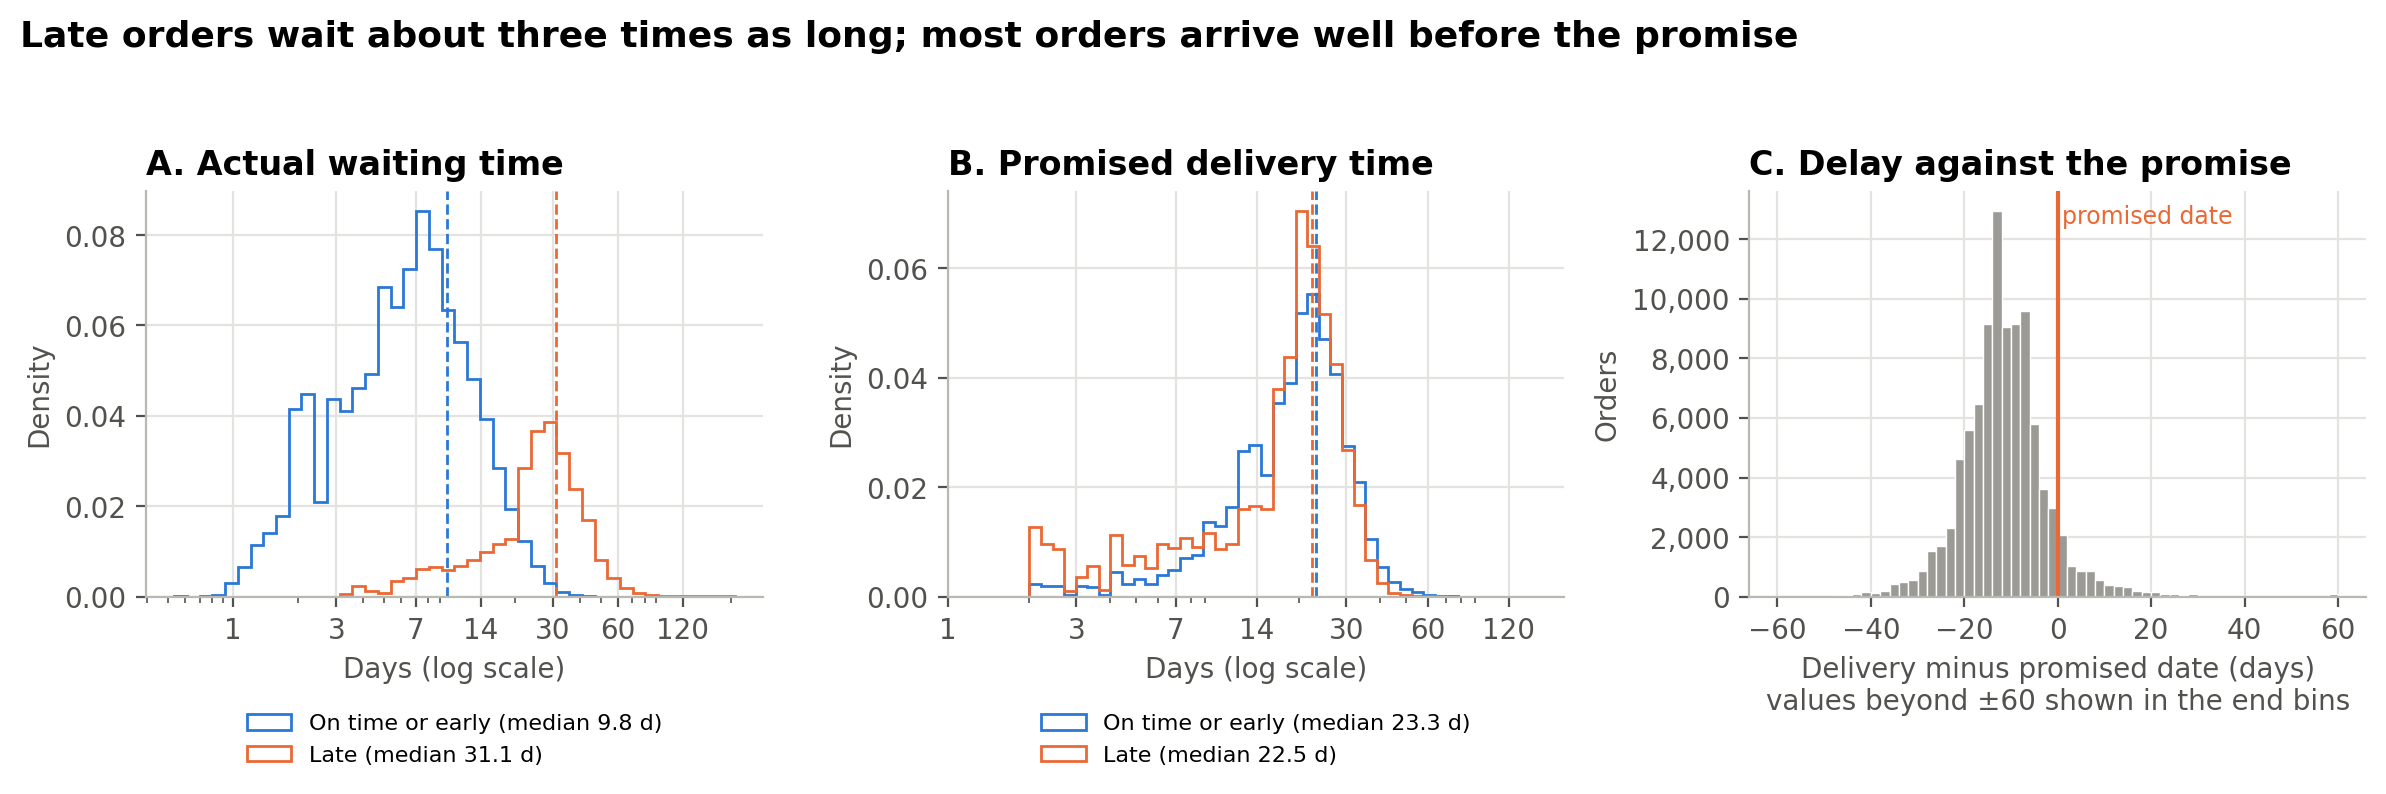

delay_days > 0 but is_late = 0: 1,269 orders delivered later in the day on the promised date (on time under D3)
Kept in the data: 290 orders waited > 60 days; 341 were > 30 days late


,n,mean,p5,p25,median,p75,p95,max
wait_days | On time or early,88943.0,10.99,2.94,6.38,9.80,14.27,23.02,70.21
wait_days | Late,6353.0,33.80,13.13,24.45,31.14,39.84,58.64,208.35
promised_days | On time or early,88943.0,23.80,10.53,18.30,23.26,28.47,38.56,155.14
promised_days | Late,6353.0,22.61,8.33,18.96,22.46,27.13,34.51,69.34
delay_days | On time or early,88943.0,-12.81,-26.22,-16.62,-12.27,-7.40,-2.08,1.00
delay_days | Late,6353.0,11.19,1.69,3.73,7.45,13.76,31.69,188.98
delay_calendar_days | On time or early,88943.0,-13.51,-27.00,-17.00,-13.00,-8.00,-3.00,0.00
delay_calendar_days | Late,6353.0,10.51,1.00,3.00,7.00,13.00,31.00,188.00


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, col, ttl in [(axes[0], "wait_days", "A. Actual waiting time"), (axes[1], "promised_days", "B. Promised delivery time")]:
    bins = np.logspace(np.log10(max(f[col].min(), 0.4)), np.log10(f[col].max()), 45)
    for k, colr in [(0, C_ON), (1, C_LATE)]:
        v = f.loc[f.is_late == k, col]
        ax.hist(v, bins=bins, density=True, histtype="step", lw=1.8, color=colr, label=f"{LABEL[k]} (median {v.median():.1f} d)")
        ax.axvline(v.median(), color=colr, ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_xticks([1, 3, 7, 14, 30, 60, 120], ["1", "3", "7", "14", "30", "60", "120"])
    ax.set(xlabel="Days (log scale)", ylabel="Density", title=ttl)
    ax.title.set_fontsize(11)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=1)
ax = axes[2]
bins = np.arange(-60, 61, 2)
ax.hist(f.delay_days.clip(-60, 60), bins=bins, color="#9b9a95", edgecolor="white", linewidth=0.5)
ax.axvline(0, color=C_LATE, lw=1.5)
ax.text(1, ax.get_ylim()[1] * 0.92, "promised date", color=C_LATE, fontsize=8.5)
ax.set(xlabel="Delivery minus promised date (days)\nvalues beyond ±60 shown in the end bins", ylabel="Orders",
       title="C. Delay against the promise")
ax.title.set_fontsize(11)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.suptitle("Late orders wait about three times as long; most orders arrive well before the promise",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
fig.subplots_adjust(bottom=0.3)
save(fig, "F06_durations", "Waiting time, promised time and delay distributions",
     "Histograms of wait_days and promised_days (log x) by lateness, and of delay_days for all orders",
     f"{len(f):,} orders; nothing trimmed (panel C pools |delay| > 60 days into the end bins: {int((f.delay_days.abs() > 60).sum())} orders)",
     "Panel C is timestamp-based: small positive delays on the promised day still count as on time under the calendar rule")

def pct(s):
    return pd.Series({"n": s.size, "mean": s.mean(), "p5": s.quantile(.05), "p25": s.quantile(.25), "median": s.median(),
                      "p75": s.quantile(.75), "p95": s.quantile(.95), "max": s.max()})
durations = pd.concat({f"{col} | {LABEL[k]}": pct(f.loc[f.is_late == k, col])
                       for col in ["wait_days", "promised_days", "delay_days", "delay_calendar_days"] for k in (0, 1)}, axis=1).T.round(2)
pos_not_late = int(((f.delay_days > 0) & (f.is_late == 0)).sum())
print(f"delay_days > 0 but is_late = 0: {pos_not_late:,} orders delivered later in the day on the promised date (on time under D3)")
print(f"Kept in the data: {int(f.flag_wait_over_60.sum())} orders waited > 60 days; {int(f.flag_delay_over_30.sum())} were > 30 days late")
durations

**`delay_days` vs `is_late`.** The promised date is stored as midnight. A parcel delivered at 3 pm on the promised day has `delay_days` = +0.6, but it arrived on the promised *calendar day*, so `is_late` = 0. `delay_calendar_days` counts whole calendar days and agrees exactly with `is_late`, which is why the delay bands below use it.

### 3. Review scores against delivery delay

**Why a 100% stacked bar per delay band?** Each bar shows the full score distribution for one band, so we see the whole shape and not just an average. The bands follow calendar weeks, chosen before looking at the scores:

- early: 15+, 8–14 and 1–7 days;
- on the promised day;
- late: 1–3, 4–7, 8–14, 15–30 and 30+ days.

Bands get wider as data thins out.

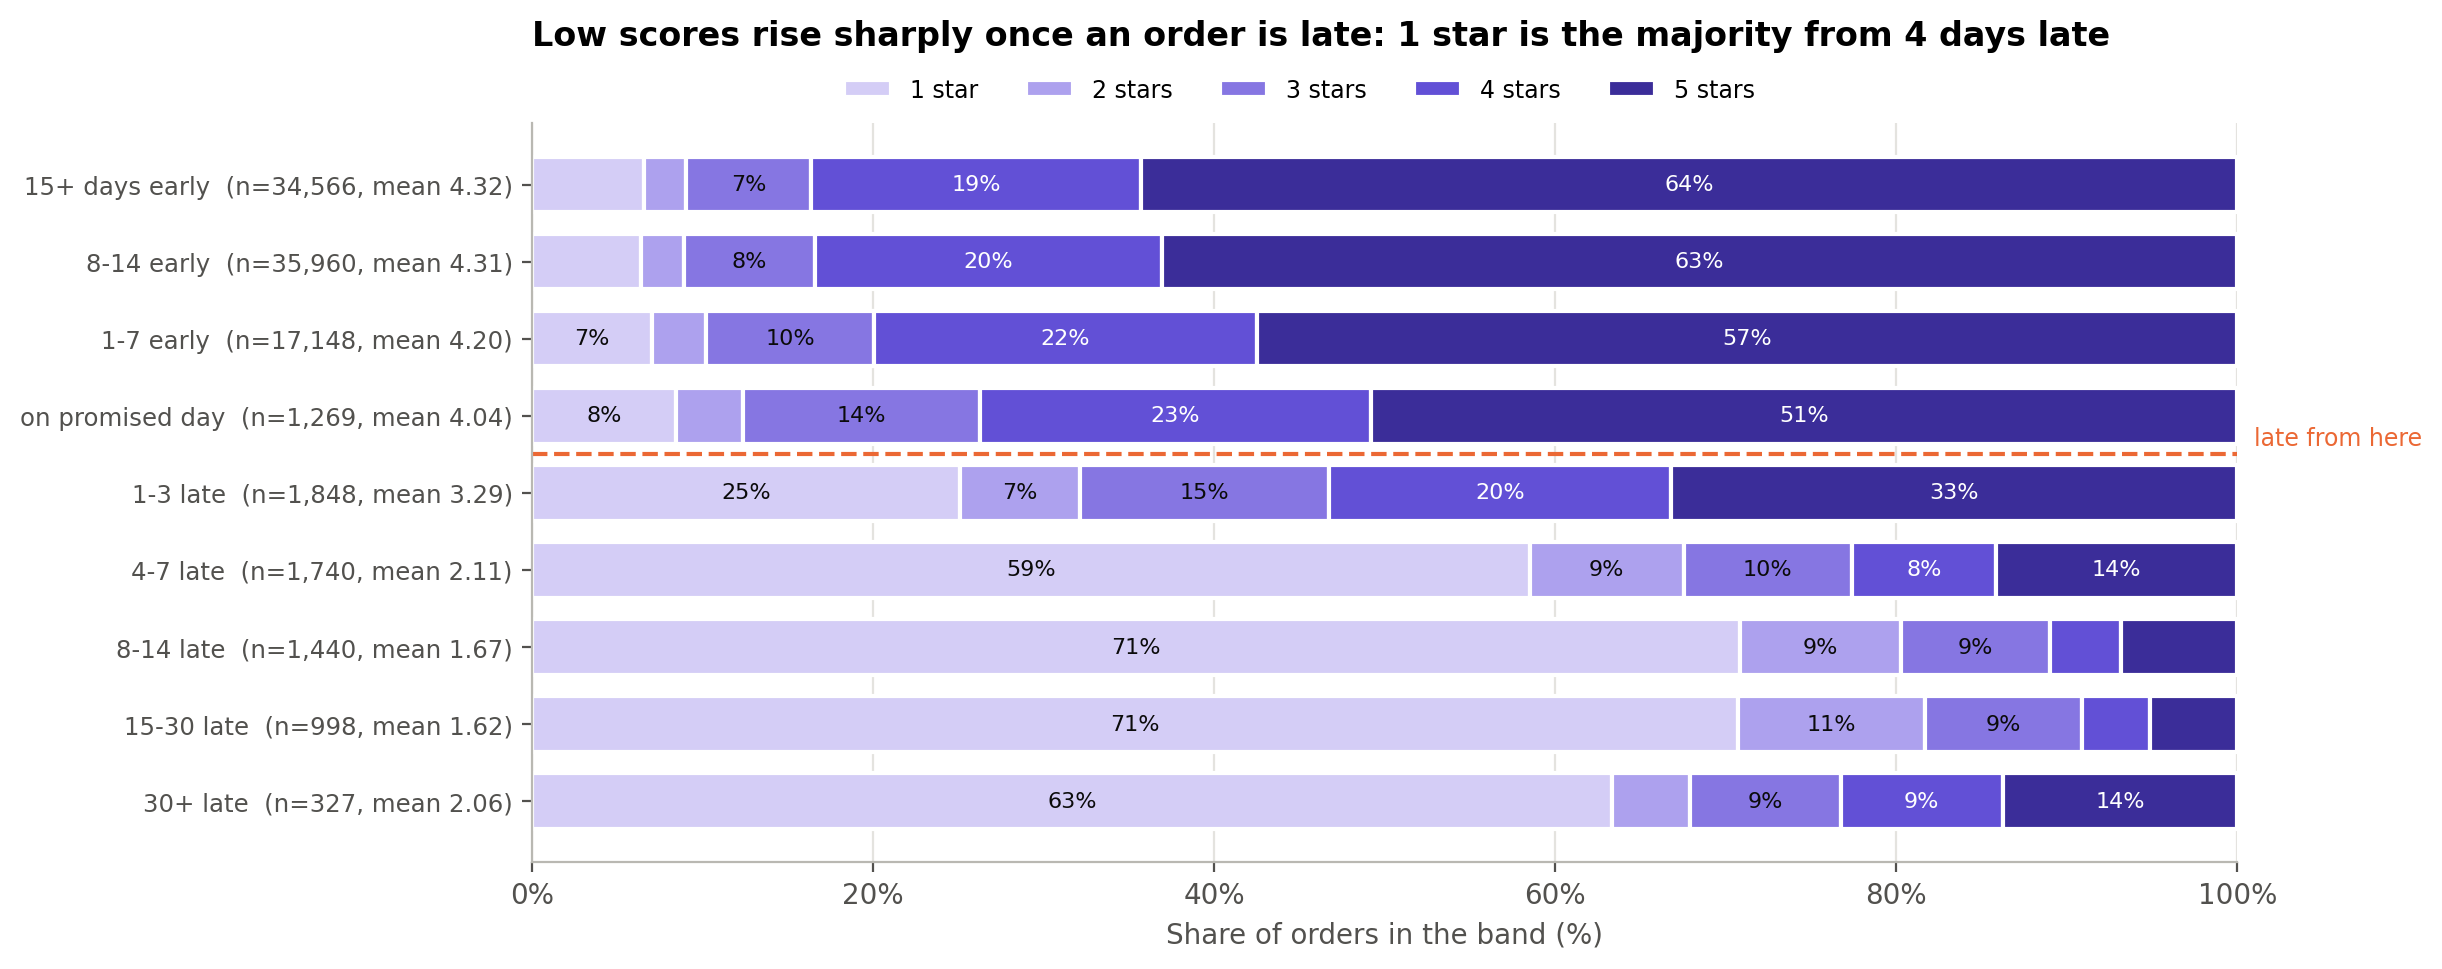

,size,mean,median
delay_band,,,
15+ days early,34566,4.32,5.0
8-14 early,35960,4.31,5.0
1-7 early,17148,4.20,5.0
on promised day,1269,4.04,5.0
1-3 late,1848,3.29,4.0
4-7 late,1740,2.11,1.0
8-14 late,1440,1.67,1.0
15-30 late,998,1.62,1.0
30+ late,327,2.06,1.0


In [9]:
DELAY_BINS = [-np.inf, -15, -8, -1, 0, 3, 7, 14, 30, np.inf]
DELAY_LABELS = ["15+ days early", "8-14 early", "1-7 early", "on promised day", "1-3 late", "4-7 late",
                "8-14 late", "15-30 late", "30+ late"]
f["delay_band"] = pd.cut(f.delay_calendar_days, DELAY_BINS, labels=DELAY_LABELS, right=True)
assert f.delay_band.notna().all()
comp = pd.crosstab(f.delay_band, f.review_score, normalize="index") * 100
nb = f.delay_band.value_counts().reindex(DELAY_LABELS)
band_stats = f.groupby("delay_band", observed=True).review_score.agg(["size", "mean", "median"])

fig, ax = plt.subplots(figsize=(11, 4.8))
left = np.zeros(len(comp))
y = np.arange(len(comp))[::-1]
for s in range(1, 6):
    ax.barh(y, comp[s], left=left, color=SCORE_RAMP[s - 1], edgecolor="white", linewidth=1.5, height=0.72, label=f"{s} star{'s' if s > 1 else ''}")
    for yi, l, v in zip(y, left, comp[s]):
        if v >= 7:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8, color=INK if s <= 3 else "white")
    left += comp[s].values
ax.set_yticks(y, [f"{b}  (n={nb[b]:,}, mean {band_stats.loc[b, 'mean']:.2f})" for b in comp.index], fontsize=8.8)
ax.axhline(y[DELAY_LABELS.index("1-3 late")] + 0.5, color=C_LATE, lw=1.5, ls="--")
ax.text(101, y[DELAY_LABELS.index("1-3 late")] + 0.55, "late from here", color=C_LATE, fontsize=8.5, va="bottom")
ax.set(xlim=(0, 100), xlabel="Share of orders in the band (%)")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.45, 1.0), fontsize=8.5)
ax.set_title("Low scores rise sharply once an order is late: 1 star is the majority from 4 days late", pad=28)
save(fig, "F07_scores_by_delay_band", "Review-score composition by delay band (calendar days vs promised date)",
     "Distribution of 1-5 star reviews within each band of delivery date minus promised date",
     f"{len(f):,} orders; band sizes on the axis",
     "Late bands are small compared with early ones; delay is tied to waiting time and to review timing (3D)")
band_stats.round(2)

**Reading it.**

- Early bands look alike, with about 57–64% 5-star reviews.
- Orders arriving **on** the promised day show fewer 5s (51%).
- Once an order is late, the 1-star share jumps: 25% at 1–3 days late, 59% at 4–7, and about 71% at 8–30 days.
- It eases slightly for the 327 orders more than 30 days late (63%). That small group may differ in other ways; for example, some may be reviewed long after the event.

This mostly rising **gradient** suggests that the size of the delay goes with the score, not just whether the order was late. It is a description: Phase 4 tests it formally with a rank correlation among late orders.

### 4. Similar waiting times: the core of the research question

Late orders also *wait longer*. So are low scores about **lateness** (a broken promise) or simply about **waiting**? A first descriptive look compares late and on-time orders **within the same waiting-time band**, in weekly bands.

The two groups overlap mainly between 2 and 6 weeks. Very short waits are almost never late, and very long waits are almost never on time, so those bands contain few orders of one group. They are labelled with their counts.

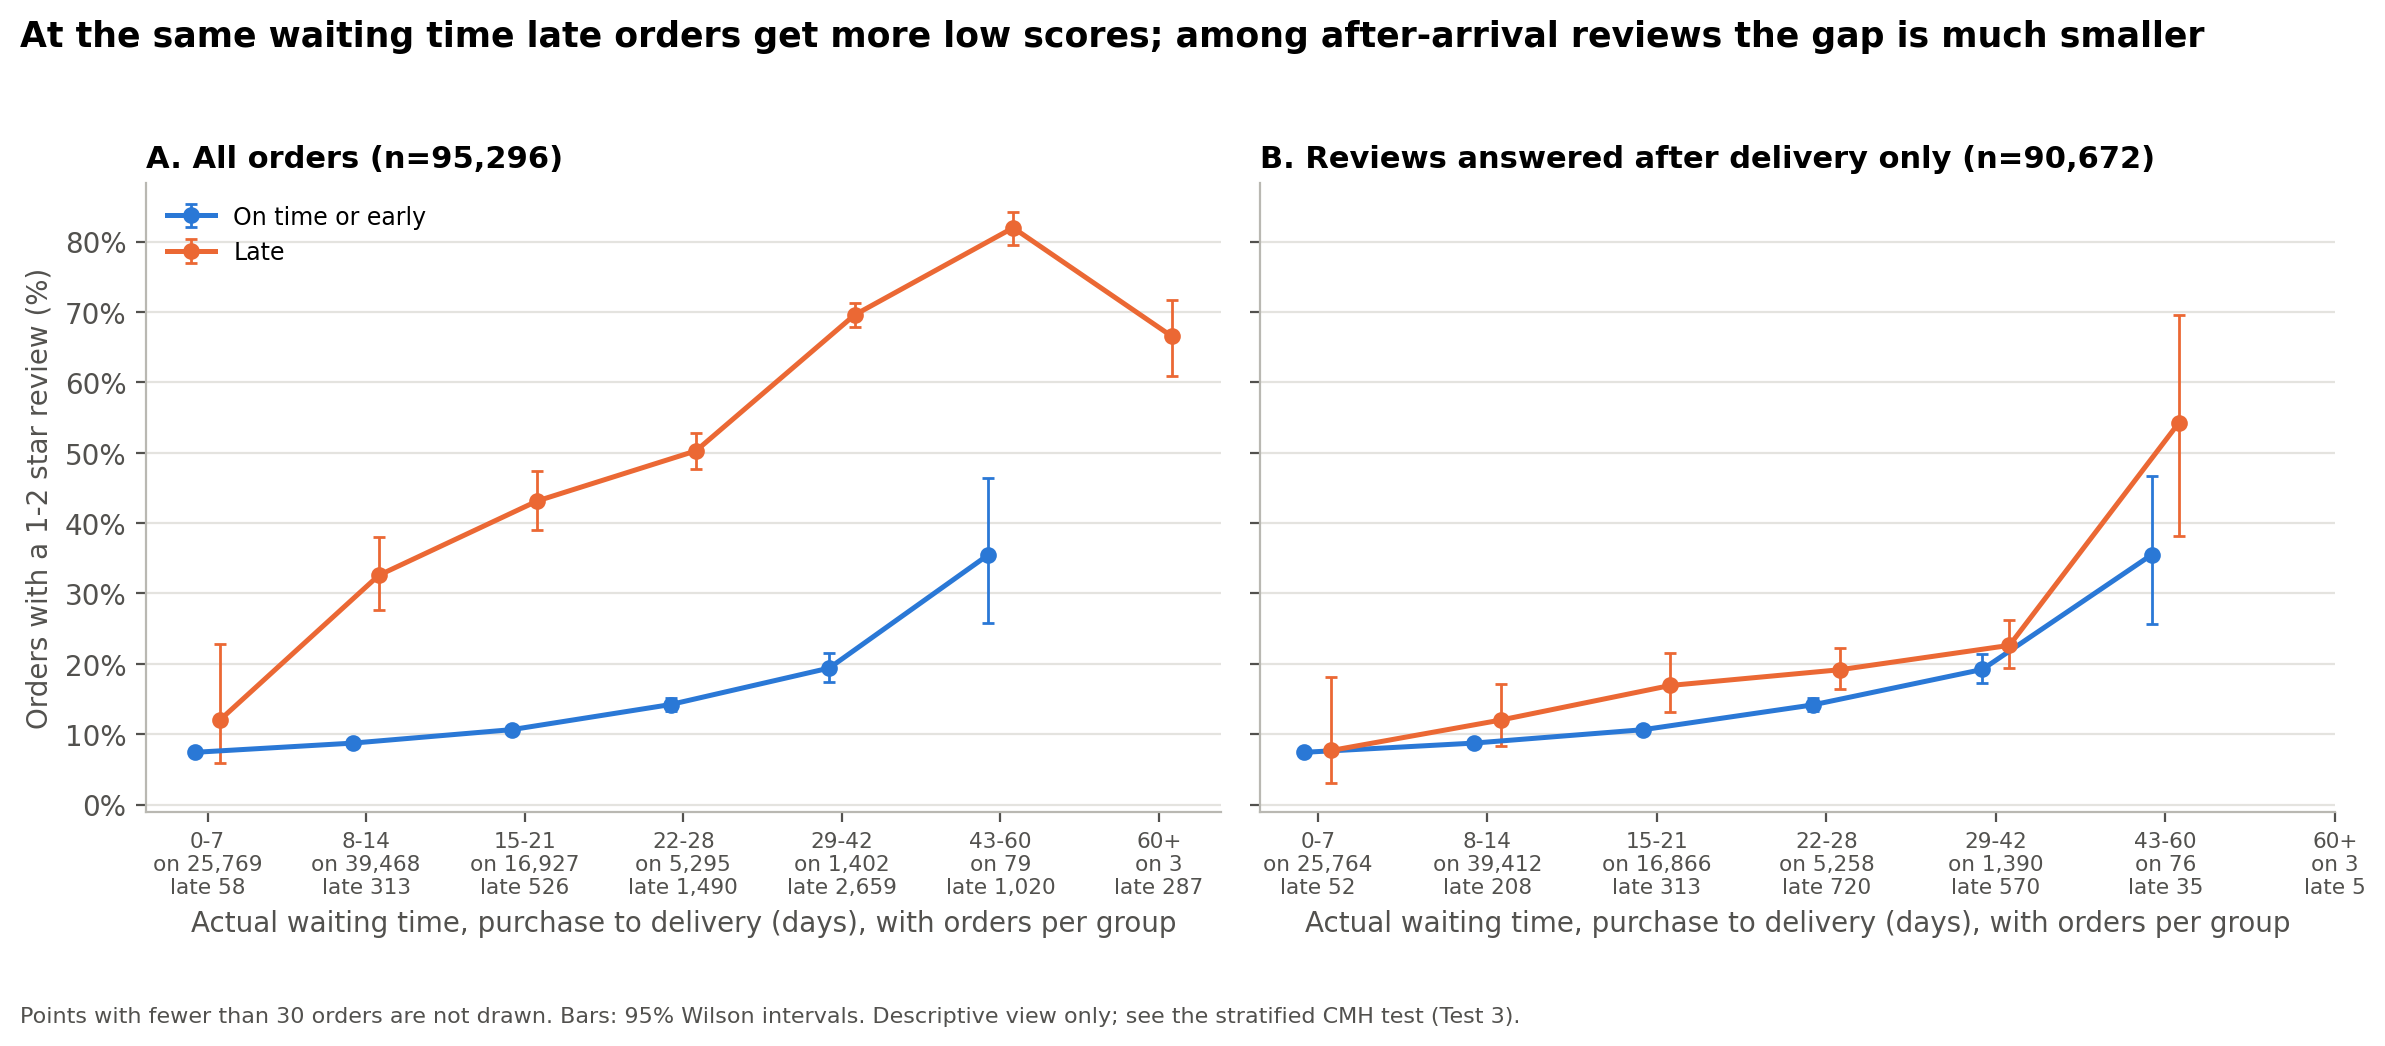

low_pct                   orders                 
group                                             Late On time or early    Late On time or early
scope                           wait_band_days                                                  
all orders                      0-7               12.1              7.4    58.0          25769.0
                                15-21             43.2             10.7   526.0          16927.0
                                22-28             50.3             14.2  1490.0           5295.0
                                29-42             69.6             19.4  2659.0           1402.0
                                43-60             82.0             35.4  1020.0             79.0
                                60+               66.6             33.3   287.0              3.0
                                8-14              32.6              8.7   313.0          39468.0
reviews answered after delivery 0-7                7.7              7.4    52.0          25764.0
                                15-21             16.9             10.6   313.0          16866.0
                                22-28             19.2             14.2   720.0           5258.0
                                29-42             22.6             19.2   570.0           1390.0
                                43-60             54.3             35.5    35.0             76.0
                                60+               20.0             33.3     5.0              3.0
                                8-14              12.0              8.7   208.0          39412.0

In [10]:
WAIT_BINS = [0, 7, 14, 21, 28, 42, 60, np.inf]
WAIT_LABELS = ["0-7", "8-14", "15-21", "22-28", "29-42", "43-60", "60+"]
f["wait_band"] = pd.cut(f.wait_days, WAIT_BINS, labels=WAIT_LABELS)
assert f.wait_band.notna().all()

def wait_table(df, scope):
    rows = []
    for (b, k), g in df.groupby(["wait_band", "is_late"], observed=False):
        n = len(g)
        lo, hi = wilson(g.low_score.sum(), n) if n else (np.nan, np.nan)
        rows.append({"scope": scope, "wait_band_days": str(b), "group": LABEL[k], "orders": n,
                     "low_pct": 100 * g.low_score.mean() if n else np.nan, "ci_low": 100 * float(lo) if n else np.nan,
                     "ci_high": 100 * float(hi) if n else np.nan, "mean_score": g.review_score.mean() if n else np.nan})
    return pd.DataFrame(rows)

wt = pd.concat([wait_table(f, "all orders"), wait_table(f[f.review_before_delivery == 0], "reviews answered after delivery")],
               ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, scope in zip(axes, ["all orders", "reviews answered after delivery"]):
    d = wt[wt.scope == scope]
    for k, colr, off in [(0, C_ON, -0.08), (1, C_LATE, 0.08)]:
        g = d[d.group == LABEL[k]].set_index("wait_band_days").reindex(WAIT_LABELS)
        ok = g.orders >= 30
        x = np.arange(len(WAIT_LABELS)) + off
        ax.errorbar(x[ok], g.low_pct[ok], yerr=[(g.low_pct - g.ci_low)[ok], (g.ci_high - g.low_pct)[ok]], fmt="o-",
                    color=colr, ms=5, lw=1.8, elinewidth=1, capsize=2, label=LABEL[k])
    on_n = d[d.group == LABEL[0]].set_index("wait_band_days").reindex(WAIT_LABELS).orders.astype(int)
    late_n = d[d.group == LABEL[1]].set_index("wait_band_days").reindex(WAIT_LABELS).orders.astype(int)
    ax.set_xticks(range(len(WAIT_LABELS)), [f"{b}\non {o:,}\nlate {l:,}" for b, o, l in zip(WAIT_LABELS, on_n, late_n)], fontsize=7.8)
    ax.set(xlabel="Actual waiting time, purchase to delivery (days), with orders per group")
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
n_after = int((f.review_before_delivery == 0).sum())
axes[0].set_title(f"A. All orders (n={len(f):,})", fontsize=11)
axes[1].set_title(f"B. Reviews answered after delivery only (n={n_after:,})", fontsize=11)
axes[0].set_ylabel("Orders with a 1-2 star review (%)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("At the same waiting time late orders get more low scores; among after-arrival reviews the gap is much smaller",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", y=1.03)
fig.text(0.01, -0.06, "Points with fewer than 30 orders are not drawn. Bars: 95% Wilson intervals. "
         "Descriptive view only; see the stratified CMH test (Test 3).", fontsize=8, color=INK2)
fig.tight_layout()
save(fig, "F08_low_score_by_wait_band", "Low-score share by waiting-time band, late vs on time (all orders and after-delivery reviews)",
     "Share of 1-2 star reviews within weekly waiting-time bands, separately for late and on-time orders",
     f"Panel A {len(f):,} orders; panel B {n_after:,} reviews answered after delivery",
     "Few late orders at short waits and few on-time orders at long waits; bands with < 30 orders not drawn")
wt.pivot_table(index=["scope", "wait_band_days"], columns="group", values=["orders", "low_pct"], observed=False).round(1)

**Reading it.**

- **Panel A, all orders.** In every waiting band, late orders have a far higher share of 1–2 star reviews than on-time orders that waited just as long. For example, at 15–21 days: 43% against 11%.
- **Panel B, reviews answered after arrival.** The gap shrinks to a few percentage points: 12% vs 9% at 8–14 days, 17% vs 11% at 15–21, 19% vs 14% at 22–28 and 23% vs 19% at 29–42. In the shortest band it is essentially zero, but only 52 late orders arrived within a week.

**Why this matters for the research question.** Among customers who had the parcel, most of the late-versus-on-time gap (19% vs 9% overall) goes along with **waiting longer**. Only a smaller part remains at equal waiting time. Most of the very large overall gap comes from customers rating while still waiting.

This is exactly what the Phase 4 stratified test must measure. It is still only a pattern: region, carrier and category are not held constant here.

---
## 3D. Review timing: a required comparison

Many late orders were reviewed **before the parcel arrived** (`review_before_delivery` = 1, comparing the customer's answer timestamp with the delivery timestamp). Those customers were rating an order they were still waiting for. Mixing them with "received" reviews could make the late-versus-on-time gap look larger than it is for delivered goods. So we split the sample into four groups.

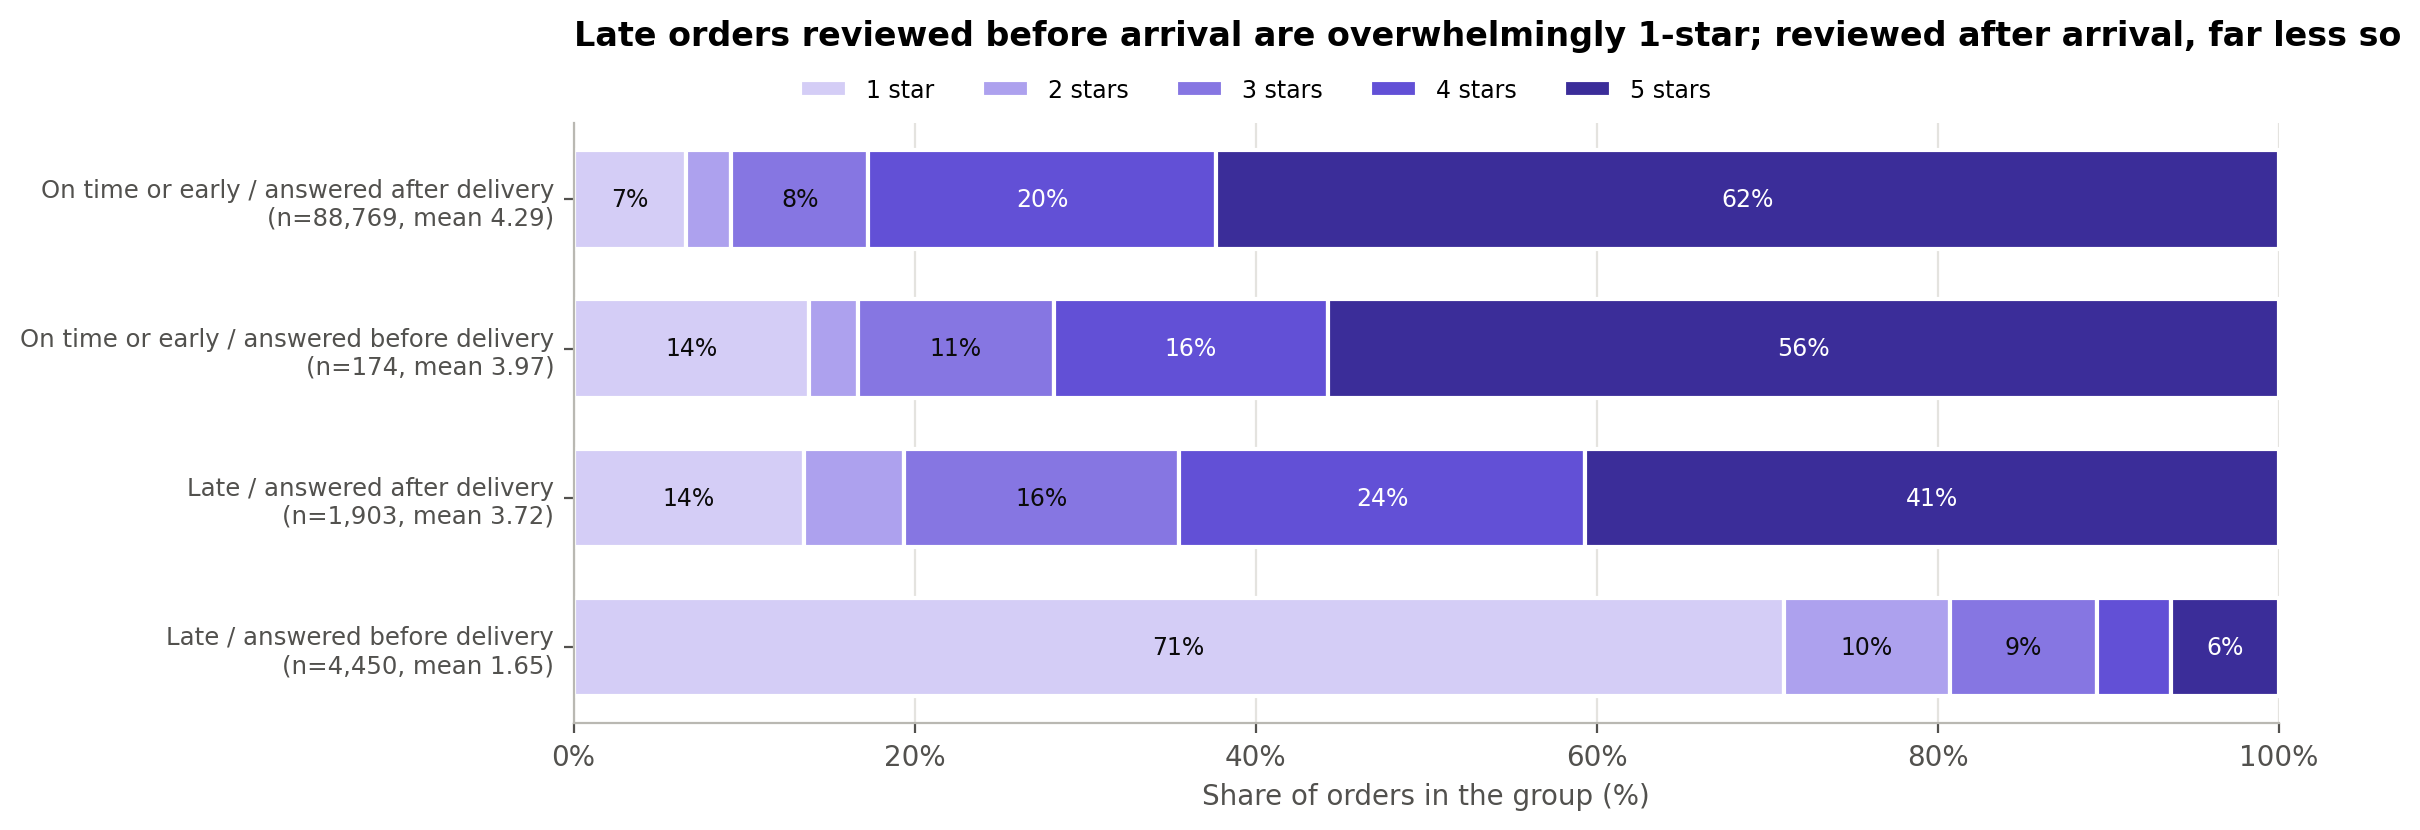

,group,delivery,review_timing,n,mean,median,sd,q1,q3,pct_low_1_2,pct_low_ci_low,pct_low_ci_high,pct_5
0,On time or early / answered after delivery,On time or early,answered after delivery,88769,4.292,5.0,1.148,4.0,5.0,9.233,9.044,9.425,62.295
1,On time or early / answered before delivery,On time or early,answered before delivery,174,3.971,5.0,1.428,3.0,5.0,16.667,11.862,22.911,55.747
2,Late / answered after delivery,Late,answered after delivery,1903,3.723,4.0,1.394,3.0,5.0,19.390,17.676,21.228,40.673
3,Late / answered before delivery,Late,answered before delivery,4450,1.653,1.0,1.190,1.0,2.0,80.742,79.557,81.873,6.292


In [11]:
rows = []
for (k, b), g in f.groupby(["is_late", "review_before_delivery"]):
    s = summarise(g.review_score)
    lo, hi = wilson((g.review_score <= 2).sum(), len(g))
    rows.append({"delivery": LABEL[k], "review_timing": "answered before delivery" if b else "answered after delivery",
                 **s, "pct_low_ci_low": 100 * float(lo), "pct_low_ci_high": 100 * float(hi)})
timing = pd.DataFrame(rows)
timing["group"] = timing.delivery + " / " + timing.review_timing
assert timing.n.sum() == len(f), "timing groups do not sum to the sample"
timing = timing[["group", "delivery", "review_timing", "n", "mean", "median", "sd", "q1", "q3", "pct_low_1_2",
                 "pct_low_ci_low", "pct_low_ci_high", "pct_5"]]
timing.round(3).to_csv(OUT3 / "p3_review_timing_groups.csv", index=False)

order = ["On time or early / answered after delivery", "On time or early / answered before delivery",
         "Late / answered after delivery", "Late / answered before delivery"]
comp4 = pd.crosstab(f.is_late.map(LABEL) + " / " + np.where(f.review_before_delivery == 1, "answered before delivery",
                                                              "answered after delivery"), f.review_score, normalize="index") * 100
comp4 = comp4.reindex(order)
t4 = timing.set_index("group").reindex(order)

fig, ax = plt.subplots(figsize=(11, 3.9))
y = np.arange(len(order))[::-1]
left = np.zeros(len(order))
for s in range(1, 6):
    ax.barh(y, comp4[s], left=left, color=SCORE_RAMP[s - 1], edgecolor="white", linewidth=1.5, height=0.66, label=f"{s} star{'s' if s > 1 else ''}")
    for yi, l, v in zip(y, left, comp4[s]):
        if v >= 6:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color=INK if s <= 3 else "white")
    left += comp4[s].values
ax.set_yticks(y, [f"{g}\n(n={int(t4.loc[g, 'n']):,}, mean {t4.loc[g, 'mean']:.2f})" for g in order], fontsize=8.8)
ax.set(xlim=(0, 100), xlabel="Share of orders in the group (%)")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.4, 1.0), fontsize=8.5)
ax.set_title("Late orders reviewed before arrival are overwhelmingly 1-star; reviewed after arrival, far less so", pad=28)
save(fig, "F09_review_timing_groups", "Score composition for late/on-time orders reviewed before or after delivery",
     "Distribution of 1-5 star reviews in the four groups defined by lateness and review timing",
     f"{len(f):,} orders: " + ", ".join(f"{g.split(' / ')[0][:4]}/{'before' if 'before' in g else 'after'} {int(t4.loc[g, 'n']):,}" for g in order),
     "Timing shows when the customer answered, not why; on-time orders answered before delivery are a small group")
timing.round(3)

In [12]:
after = f[f.review_before_delivery == 0]
after_cmp = pd.DataFrame([{"comparison": "all orders", "group": LABEL[k], **summarise(g.review_score)} for k, g in f.groupby("is_late")] +
                         [{"comparison": "reviews answered after delivery", "group": LABEL[k], **summarise(g.review_score)}
                          for k, g in after.groupby("is_late")]).round(3)
gap = after_cmp.pivot(index="comparison", columns="group", values=["mean", "pct_low_1_2"])
gap[("difference", "mean (late - on time)")] = gap[("mean", "Late")] - gap[("mean", "On time or early")]
gap[("difference", "low-score pp (late - on time)")] = gap[("pct_low_1_2", "Late")] - gap[("pct_low_1_2", "On time or early")]
display(after_cmp)
gap.round(2)

,comparison,group,n,mean,median,sd,q1,q3,pct_low_1_2,pct_5
0,all orders,On time or early,88943,4.291,5.0,1.148,4.0,5.0,9.247,62.283
1,all orders,Late,6353,2.273,1.0,1.573,1.0,4.0,62.364,16.591
2,reviews answered after delivery,On time or early,88769,4.292,5.0,1.148,4.0,5.0,9.233,62.295
3,reviews answered after delivery,Late,1903,3.723,4.0,1.394,3.0,5.0,19.390,40.673


mean                  pct_low_1_2                             difference                              
group                            Late On time or early        Late On time or early mean (late - on time) low-score pp (late - on time)
comparison                                                                                                                             
all orders                       2.27             4.29       62.36             9.25                 -2.02                         53.12
reviews answered after delivery  3.72             4.29       19.39             9.23                 -0.57                         10.16

**Why this matters.** In all orders, the late-minus-on-time gap mixes two things: (1) late parcels that customers had received, and (2) customers who were still waiting when they answered. Among reviews answered **after** delivery, the gap is smaller but still large. On-time orders average about 4.3 stars against about 3.7 for late orders, and the low-score share is roughly twice as high.

So pre-delivery reviews **inflate** the overall gap without creating it. Section 3C.4 adds that, among after-delivery reviews, much of the remaining gap goes with longer waiting. We do not claim that pre-delivery reviews are "wrong": a customer still waiting past the promised date is giving genuine feedback about that experience. They stay in the main dataset, and Phase 4 runs the formal sensitivity analysis.

---
## 3E. Text exploration

### 1. Comment availability

- `has_comment` = 1 when the **message** contains text.
- `has_any_text` = 1 when the message **or the title** contains text.

A title-only review ("Produto excelente", no message) is written feedback. It counts for `has_any_text` but not for `has_comment`.

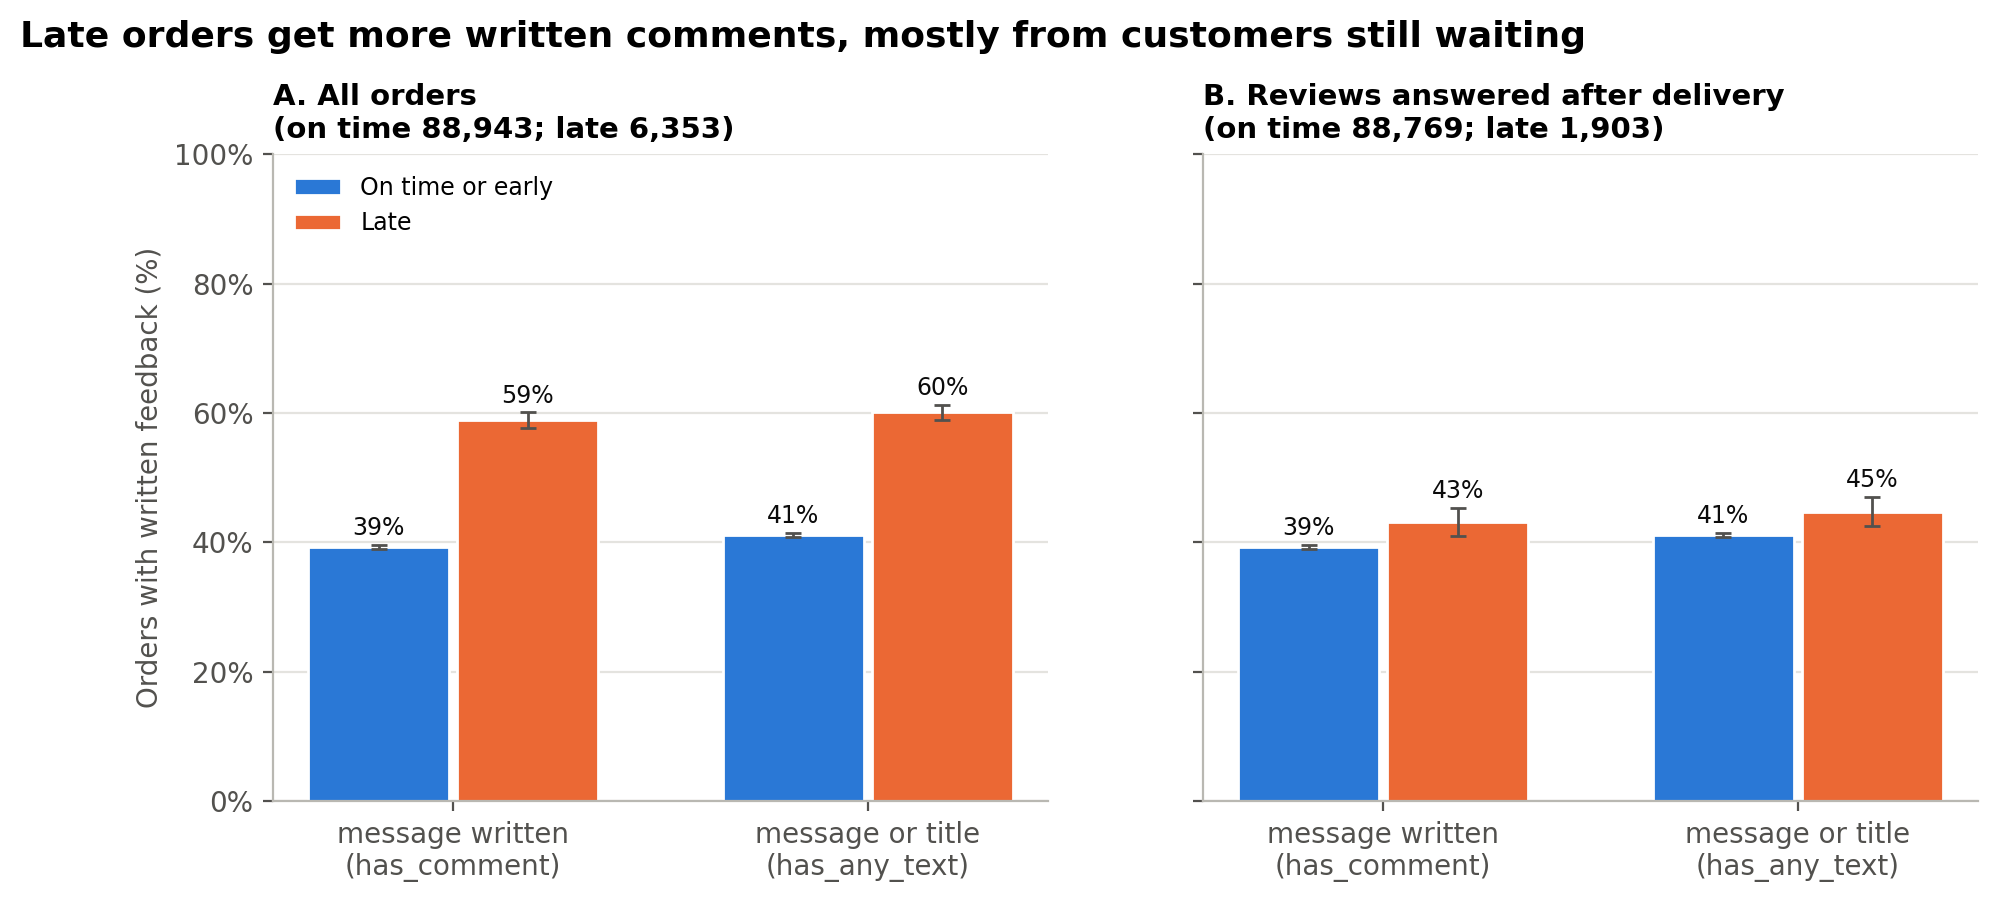

,scope,group,variable,orders,with_text,pct,ci_low,ci_high
0,all orders,On time or early,has_comment,88943,34952,39.30,38.98,39.62
1,all orders,On time or early,has_any_text,88943,36579,41.13,40.80,41.45
2,all orders,Late,has_comment,6353,3744,58.93,57.72,60.14
3,all orders,Late,has_any_text,6353,3818,60.10,58.89,61.30
4,reviews answered after delivery,On time or early,has_comment,88769,34886,39.30,38.98,39.62
5,reviews answered after delivery,On time or early,has_any_text,88769,36512,41.13,40.81,41.46
6,reviews answered after delivery,Late,has_comment,1903,821,43.14,40.93,45.38
7,reviews answered after delivery,Late,has_any_text,1903,852,44.77,42.55,47.01


In [13]:
avail = []
for scope, df in [("all orders", f), ("reviews answered after delivery", after)]:
    for k, g in df.groupby("is_late"):
        for var in ["has_comment", "has_any_text"]:
            lo, hi = wilson(g[var].sum(), len(g))
            avail.append({"scope": scope, "group": LABEL[k], "variable": var, "orders": len(g), "with_text": int(g[var].sum()),
                          "pct": 100 * g[var].mean(), "ci_low": 100 * float(lo), "ci_high": 100 * float(hi)})
avail = pd.DataFrame(avail)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, scope in zip(axes, ["all orders", "reviews answered after delivery"]):
    d = avail[avail.scope == scope]
    for i, var in enumerate(["has_comment", "has_any_text"]):
        for j, (k, colr) in enumerate([(0, C_ON), (1, C_LATE)]):
            r = d[(d.variable == var) & (d.group == LABEL[k])].iloc[0]
            xpos = i + (j - 0.5) * 0.36
            ax.bar(xpos, r.pct, width=0.34, color=colr, edgecolor="white", label=LABEL[k] if i == 0 else None)
            ax.errorbar(xpos, r.pct, yerr=[[r.pct - r.ci_low], [r.ci_high - r.pct]], color=INK2, capsize=3, lw=1)
            ax.text(xpos, r.ci_high + 1.5, f"{r.pct:.0f}%", ha="center", fontsize=8.5, color=INK)
    ax.set_xticks([0, 1], ["message written\n(has_comment)", "message or title\n(has_any_text)"])
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
    n_on, n_late = d[d.group == LABEL[0]].orders.iloc[0], d[d.group == LABEL[1]].orders.iloc[0]
    ax.set_title(f"{'A' if scope == 'all orders' else 'B'}. {scope.capitalize()}\n(on time {n_on:,}; late {n_late:,})", fontsize=10.5)
axes[0].set_ylabel("Orders with written feedback (%)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Late orders get more written comments, mostly from customers still waiting", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
save(fig, "F10_comment_availability", "Share of orders with written feedback, by lateness",
     "Share with a message (has_comment) and with a message or title (has_any_text), all orders and after-delivery reviews",
     f"{len(f):,} orders; panel B {len(after):,}",
     "Writing a comment is a choice; the share says how often people write, not what they write")
avail.round(2)

**Reading it.** Across all orders, 59% of late orders carry a message against 39% of on-time orders. Among reviews answered after delivery, the difference shrinks to about 4 points (43% vs 39%). So most of the extra writing comes from customers who were still waiting, and who explain why they are unhappy.

The gap between `has_comment` and `has_any_text` is small, a few percentage points from title-only reviews, so the choice of definition does not change the picture. Phase 4 test 5 should still state which one it uses.

### 2. Comment length

**Convention.** Length is the number of characters in the trimmed message. Orders **without** a message are **left out** here instead of being counted as zero, because "no comment" is a different thing from "a very short comment". Title-only reviews have no message, so they are not included.

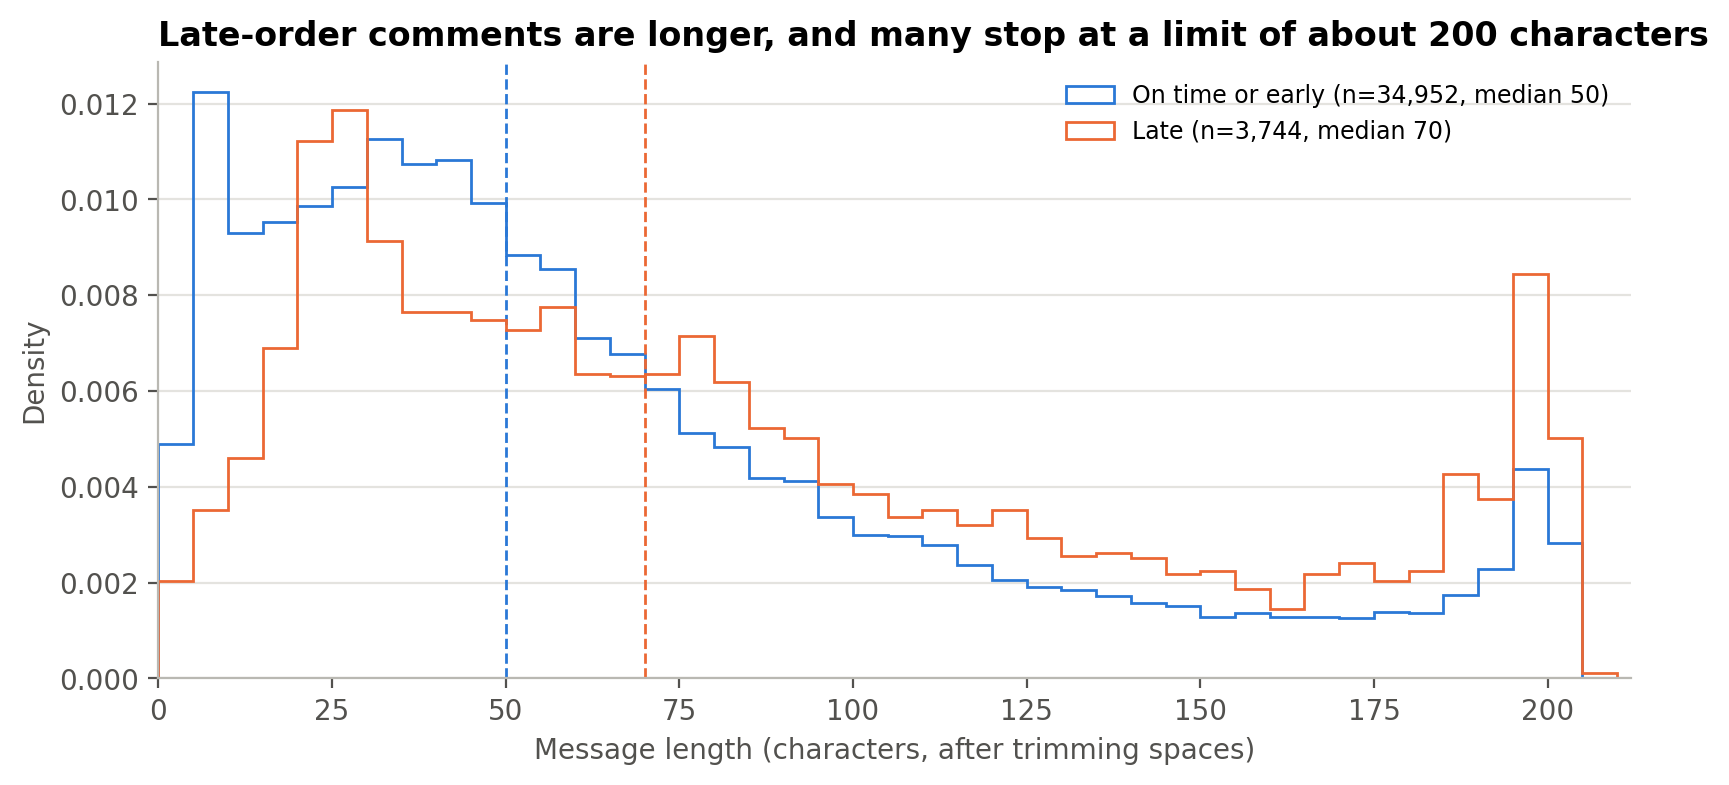

,group,messages,mean,p10,p25,median,p75,p90,max,share_ge_190_chars
0,On time or early,34952,65.3,11.0,27.0,50.0,89.0,151.0,207,4.7
1,Late,3744,84.0,20.0,35.0,70.0,122.0,187.0,208,8.7


In [14]:
msg = f[f.has_comment == 1]
len_rows = []
for k, g in msg.groupby("is_late"):
    s = g.comment_len_chars
    len_rows.append({"group": LABEL[k], "messages": len(s), "mean": s.mean(), "p10": s.quantile(.1), "p25": s.quantile(.25),
                     "median": s.median(), "p75": s.quantile(.75), "p90": s.quantile(.9), "max": s.max(),
                     "share_ge_190_chars": 100 * (s >= 190).mean()})
length = pd.DataFrame(len_rows)
near_cap = int((msg.comment_len_chars >= 190).sum())

fig, ax = plt.subplots(figsize=(9.5, 4))
bins = np.arange(0, 215, 5)
for k, colr in [(0, C_ON), (1, C_LATE)]:
    v = msg.loc[msg.is_late == k, "comment_len_chars"]
    ax.hist(v, bins=bins, density=True, histtype="step", lw=2, color=colr, label=f"{LABEL[k]} (n={len(v):,}, median {v.median():.0f})")
    ax.axvline(v.median(), color=colr, ls="--", lw=1)
ax.set(xlabel="Message length (characters, after trimming spaces)", ylabel="Density", xlim=(0, 212))
ax.legend(fontsize=8.5)
ax.grid(axis="x", visible=False)
ax.set_title("Late-order comments are longer, and many stop at a limit of about 200 characters")
save(fig, "F11_comment_length", "Distribution of message length among orders with a message, by lateness",
     "Histogram of characters per message for late vs on-time orders; dashed lines are medians",
     f"{len(msg):,} orders with a message (missing and whitespace-only messages excluded)",
     f"Lengths stop at {int(msg.comment_len_chars.max())} characters; {near_cap:,} messages are 190+, suggesting a form limit")
length.round(1)

**Reading it.** Late-order messages are longer on average: complaints take more words to explain.

The distribution ends abruptly near 200 characters. That looks like a length limit on the review form, so the longest messages may be cut off and "length" cannot grow past it. We note this; we do not correct it.

### 3. Most common words

**Method.** The original text is never changed: the steps below are applied to a copy.

1. **Normalise:** lowercase, remove accents (`não` → `nao`), and keep only letter runs, which drops punctuation and digits.
2. **Remove stopwords:** use the 329-word Portuguese list in `resources/stopwords_pt.txt`. Six words are deliberately kept because they carry meaning in reviews: `nao`, `nem`, `sem` (negation) and `bom`, `bem`, `antes` (evaluation and timing).
3. **Drop** tokens shorter than 2 letters.
4. **Measure** each word by the **share of messages that contain it**, which is easy to interpret and is not distorted by one long comment repeating a word.

Only messages with text are used (`has_comment` = 1), so missing and whitespace-only messages are excluded. Word frequency is **not sentiment**: "prazo" (deadline) appears in "chegou antes do prazo" (arrived early) and in "fora do prazo" (late).

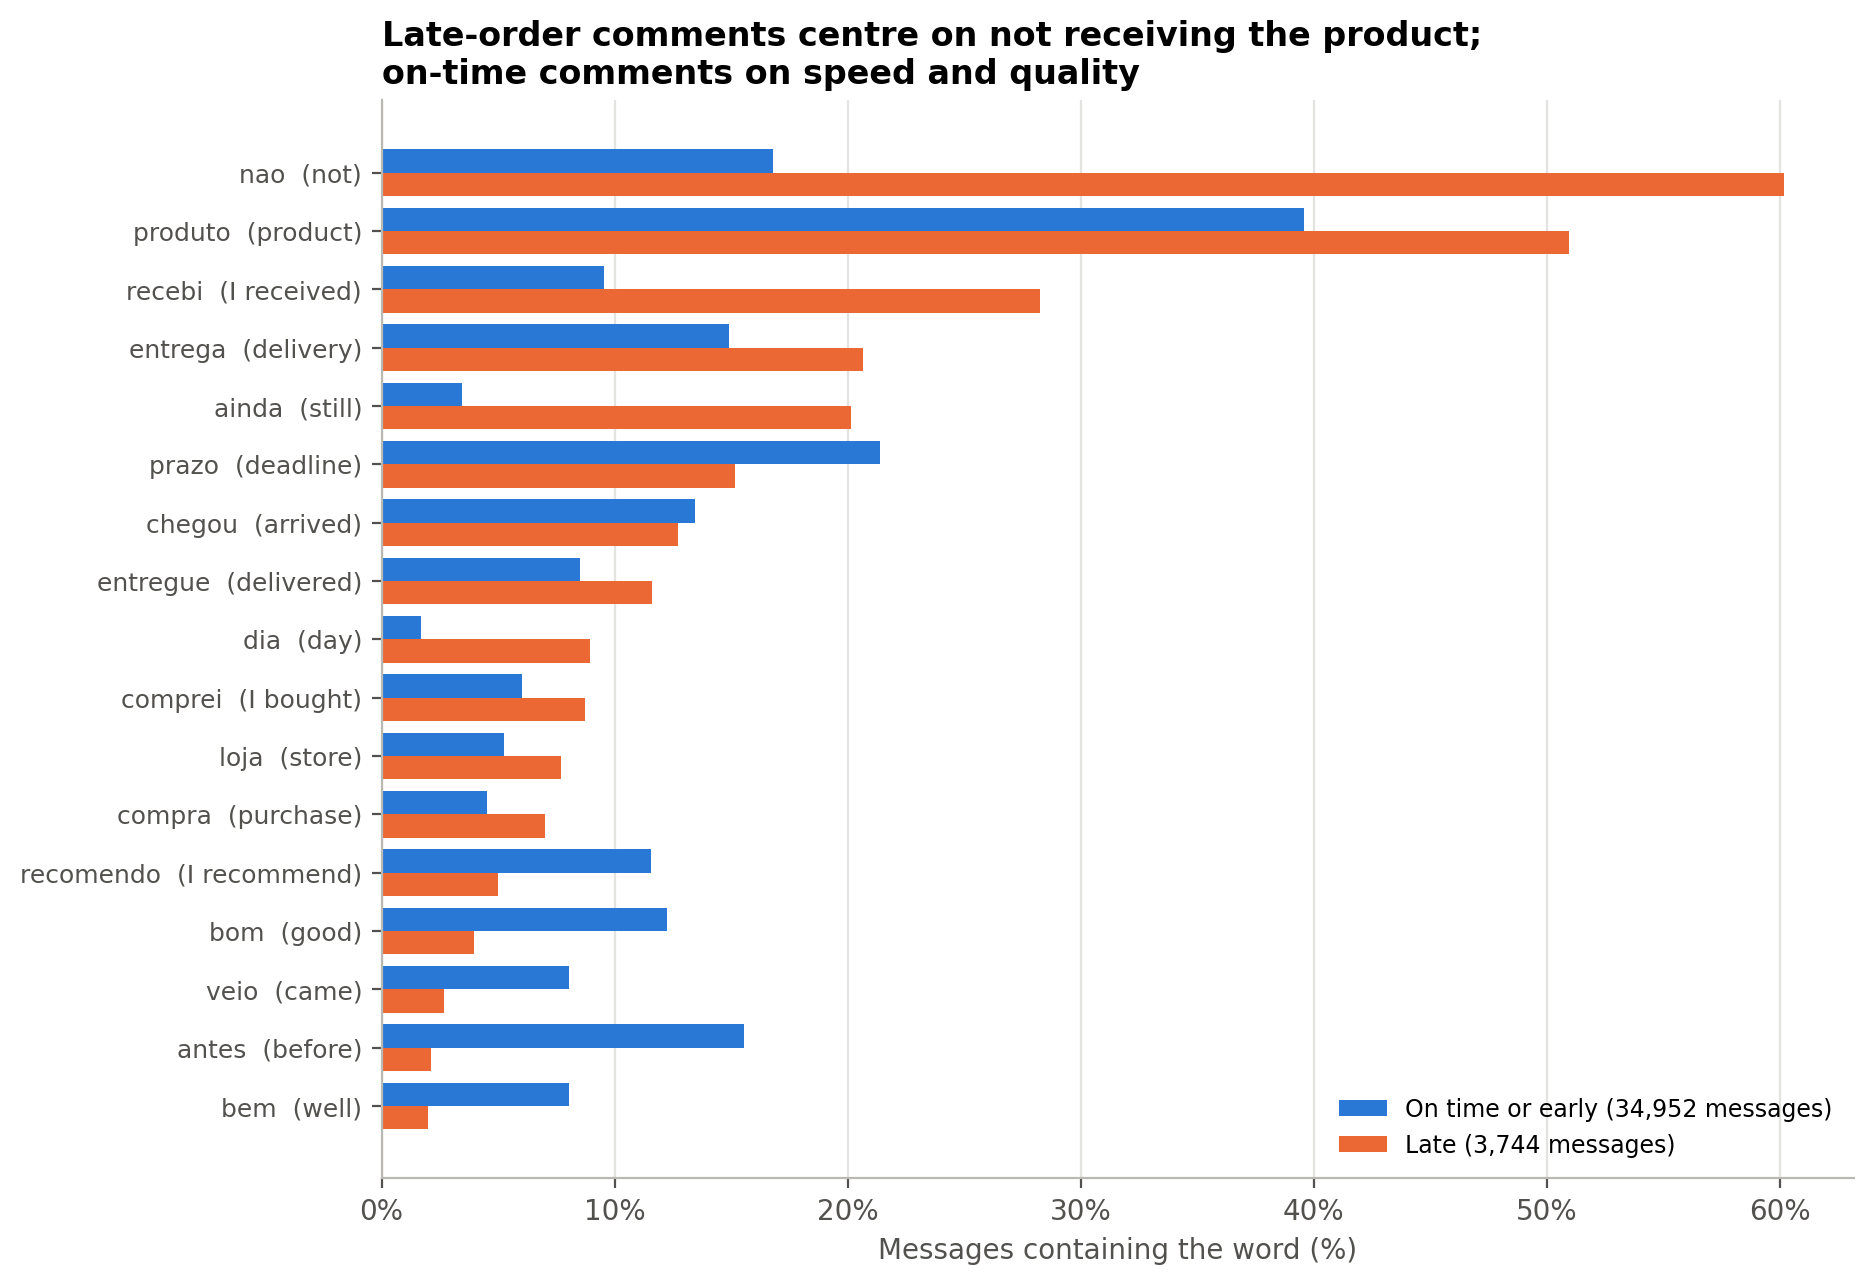

Messages analysed: 38,696 | stopwords used: 313 (kept on purpose: ['antes', 'bem', 'bom', 'nao', 'nem', 'sem'])


,word,late,on_time
0,nao,60.2,16.8
1,produto,51.0,39.6
2,recebi,28.3,9.5
3,entrega,20.6,14.9
4,ainda,20.1,3.4
5,prazo,15.2,21.4
6,chegou,12.7,13.5
7,entregue,11.6,8.5
8,dia,8.9,1.7
9,comprei,8.7,6.0


In [15]:
raw_stop = [w.strip() for w in open("resources/stopwords_pt.txt", encoding="utf-8") if w.strip() and not w.startswith("#")]
def norm(s):
    s = unicodedata.normalize("NFKD", s.lower())
    return "".join(ch for ch in s if not unicodedata.combining(ch))
KEEP = {"nao", "nem", "sem", "bom", "bem", "antes"}
STOP = {norm(w) for w in raw_stop} - KEEP
TOKEN = re.compile(r"[a-z]+")

def tokens(text):
    return [t for t in TOKEN.findall(norm(text)) if len(t) >= 2 and t not in STOP]

msg_tokens = msg.review_comment_message.map(lambda s: set(tokens(s)))   # set: count each word once per message
assert (msg.review_comment_message.str.strip() != "").all()
assert f.review_comment_message.equals(pd.read_parquet(P2 / "analysis_table_final.parquet").review_comment_message), "text changed"

def top_words(mask, k=15):
    docs = msg_tokens[mask.values]
    c = Counter(w for d in docs for w in d)
    n = len(docs)
    return pd.DataFrame([{"word": w, "messages_containing": c[w], "share_pct": 100 * c[w] / n} for w, _ in c.most_common(k)]), n, c

word_rows = []
for scope, smask in [("all messages", pd.Series(True, index=msg.index)), ("after-delivery messages", msg.review_before_delivery == 0)]:
    for k in (0, 1):
        tw, n, _ = top_words(smask & (msg.is_late == k), 25)
        tw.insert(0, "rank", range(1, len(tw) + 1))
        word_rows.append(tw.assign(scope=scope, group=LABEL[k], messages_in_group=n))
top_words_table = pd.concat(word_rows, ignore_index=True)
top_words_table.round(2).to_csv(OUT3 / "p3_top_words.csv", index=False)

_, n_on, c_on = top_words(msg.is_late == 0)
_, n_late, c_late = top_words(msg.is_late == 1)
union = list(dict.fromkeys([w for w, _ in c_late.most_common(12)] + [w for w, _ in c_on.most_common(12)]))
wd = pd.DataFrame({"word": union, "late": [100 * c_late[w] / n_late for w in union],
                   "on_time": [100 * c_on[w] / n_on for w in union]}).sort_values("late")

fig, ax = plt.subplots(figsize=(9.5, 7))
y = np.arange(len(wd))
ax.barh(y + 0.2, wd.on_time, height=0.4, color=C_ON, label=f"On time or early ({n_on:,} messages)")
ax.barh(y - 0.2, wd.late, height=0.4, color=C_LATE, label=f"Late ({n_late:,} messages)")
GLOSS = {"nao": "not", "produto": "product", "recebi": "I received", "entrega": "delivery", "ainda": "still", "prazo": "deadline",
         "chegou": "arrived", "entregue": "delivered", "dia": "day", "comprei": "I bought", "loja": "store", "compra": "purchase",
         "recomendo": "I recommend", "bom": "good", "veio": "came", "antes": "before", "bem": "well", "qualidade": "quality",
         "otimo": "great", "tudo": "everything", "rapido": "fast", "excelente": "excellent", "super": "super", "muito": "very",
         "pedido": "order", "agora": "now", "certo": "right", "perfeito": "perfect", "gostei": "I liked", "sem": "without"}
ax.set_yticks(y, [f"{w}  ({GLOSS.get(w, '?')})" for w in wd.word], fontsize=9)
ax.set(xlabel="Messages containing the word (%)")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8.5)
ax.set_title("Late-order comments centre on not receiving the product;\non-time comments on speed and quality")
save(fig, "F12_top_words", "Most common words in review messages, late vs on time (stopwords removed)",
     "Union of the 12 most common words in each group; bars show the share of messages containing the word",
     f"{len(msg):,} messages with text ({n_on:,} on time or early, {n_late:,} late)",
     "Word frequency is not sentiment; accents removed; negation words kept on purpose; Portuguese, untranslated")
print(f"Messages analysed: {len(msg):,} | stopwords used: {len(STOP)} (kept on purpose: {sorted(KEEP)})")
wd.sort_values("late", ascending=False).round(1)

**Reading it.** The two vocabularies tell different stories.

- **Late-order messages:**
    - `nao` ("not") appears in 60% of them, against 17% of on-time messages.
    - `recebi` ("I received") appears in 28%, and `ainda` ("still") in 20%, against 3% on time.
    - The phrase check in the next cell confirms the reading: "nao recebi" ("I didn't receive it") appears in about a quarter of late messages.
- **On-time messages** favour `antes` ("before", as in "chegou antes do prazo"), `bom` (good), `recomendo` (I recommend) and `qualidade` (quality).
- **Late orders reviewed after arrival** (in the CSV) look much closer to on-time messages, with `nao` in 26%.

Words like `produto`, `entrega` and `prazo` are common to both groups. Without the context, a word count cannot say whether a mention is positive or negative.

In [16]:
# Phrase check: do the single words really come from the phrases we think? (same normalisation, no stopword removal)
norm_text = msg.review_comment_message.map(lambda s: " ".join(TOKEN.findall(norm(s))))
PHRASES = {"nao recebi": "I didn't receive (it)", "ainda nao recebi": "I still haven't received (it)",
           "antes do prazo": "before the deadline", "dentro do prazo": "within the deadline", "recomendo": "I recommend"}
phr = []
for ph, meaning in PHRASES.items():
    for k in (0, 1):
        t_ = norm_text[msg.is_late.values == k]
        phr.append({"phrase": ph, "meaning": meaning, "group": LABEL[k], "messages": len(t_),
                    "share_pct": 100 * t_.str.contains(rf"\b{ph}\b", regex=True).mean()})
phrases = pd.DataFrame(phr)
phrases.pivot(index=["phrase", "meaning"], columns="group", values="share_pct").round(1)

,group,Late,On time or early
phrase,meaning,,
ainda nao recebi,I still haven't received (it),7.5,0.4
antes do prazo,before the deadline,0.9,11.6
dentro do prazo,within the deadline,0.9,2.9
nao recebi,I didn't receive (it),24.4,1.9
recomendo,I recommend,5.0,11.6


---
## 3G. Summary tables and outputs

In [17]:
main = []
for _, r in score_summary.iterrows():
    main.append({"comparison": "review score", "group": r.group, "n": r.n, "mean": r["mean"], "median": r["median"],
                 "sd": r.sd, "q1": r.q1, "q3": r.q3, "pct_low_1_2": r.pct_low_1_2, "pct_5": r.pct_5, "note": ""})
for _, r in after_cmp[after_cmp.comparison == "reviews answered after delivery"].iterrows():
    main.append({"comparison": "review score, after-delivery reviews only", "group": r.group, "n": r.n, "mean": r["mean"],
                 "median": r["median"], "sd": r.sd, "q1": r.q1, "q3": r.q3, "pct_low_1_2": r.pct_low_1_2, "pct_5": r.pct_5,
                 "note": f"excludes {int(f.review_before_delivery.sum()):,} reviews answered before delivery"})
for b in DELAY_LABELS:
    g = f[f.delay_band == b].review_score
    s = summarise(g)
    main.append({"comparison": "review score by delay band (calendar days)", "group": b, **s, "note": ""})
for _, r in wt.iterrows():
    main.append({"comparison": f"low-score share by wait band ({r.scope})", "group": f"{r.wait_band_days} days | {r.group}",
                 "n": r.orders, "mean": r.mean_score, "pct_low_1_2": r.low_pct, "note": "plotted only if n >= 30"})
for _, r in order_bins.iterrows():
    main.append({"comparison": f"low-score share by {r.variable}", "group": f"{r.bin} | {r.group}", "n": r.orders,
                 "mean": r.mean_score, "pct_low_1_2": r.low_pct, "note": ""})
for idx, r in durations.iterrows():
    main.append({"comparison": "duration (days)", "group": idx, "n": r.n, "mean": r["mean"], "median": r["median"],
                 "q1": r.p25, "q3": r.p75, "note": f"p5 {r.p5:.1f}, p95 {r.p95:.1f}, max {r['max']:.1f}"})
main = pd.DataFrame(main)
main.round(3).to_csv(OUT3 / "p3_main_summaries.csv", index=False)

m.round(3).to_csv(OUT3 / "p3_monthly.csv", index=False)
sc = pd.concat([st.assign(level="customer_state").rename(columns={"customer_state": "name"}),
                cat.assign(level="dominant_category").rename(columns={"dominant_category": "name"})], ignore_index=True)
sc.round(3).to_csv(OUT3 / "p3_state_category_summary.csv", index=False)
text_summary = pd.concat([avail.assign(table="comment availability"),
                          length.assign(table="message length (has_comment = 1 only)", scope="all orders"),
                          phrases.assign(table="phrase share (messages with text)", scope="all orders")], ignore_index=True)
text_summary.round(3).to_csv(OUT3 / "p3_text_summary.csv", index=False)
fig_index = pd.DataFrame(FIGURES)
fig_index.to_csv(OUT3 / "p3_figure_index.csv", index=False)
print("Wrote:", sorted(p.name for p in OUT3.glob("*.csv")))
print("Figures:", len(fig_index))

Wrote: ['p3_figure_index.csv', 'p3_final_checks.csv', 'p3_main_summaries.csv', 'p3_monthly.csv', 'p3_review_timing_groups.csv', 'p3_state_category_summary.csv', 'p3_text_summary.csv', 'p3_top_words.csv', 'p3_validation.csv']
Figures: 12


## 3I. Final validation

In [18]:
final_checks = {
    "sample unchanged (95,296 rows, Phase 2 table untouched)": len(pd.read_parquet(P2 / "analysis_table_final.parquet")) == len(f) == 95_296,
    "monthly totals = sample": int(m.orders.sum()) == len(f),
    "main-trend months + 2016 months = sample": int(m[m.in_main_trend].orders.sum()) + int(m[~m.in_main_trend].orders.sum()) == len(f),
    "state totals = sample": int(st.orders.sum()) == len(f),
    "category totals = sample": int(cat.orders.sum()) == len(f),
    "figure categories all have >= 1,000 orders": bool((big_cat.orders >= 1000).all()),
    "review-timing groups sum to sample": int(timing.n.sum()) == len(f),
    "delay bands cover every order": int(nb.sum()) == len(f),
    "wait bands cover every order": int(wt[wt.scope == "all orders"].orders.sum()) == len(f),
    "after-delivery subset = sample - answered before delivery": len(after) == len(f) - int(f.review_before_delivery.sum()),
    "text analysis uses only non-blank messages": len(msg) == int(f.has_comment.sum()) and int(msg.flag_whitespace_comment.sum()) == 0,
    "comment-availability groups sum to sample": int(avail[(avail.scope == "all orders") & (avail.variable == "has_comment")].orders.sum()) == len(f),
    "every figure file exists": all(Path(p).exists() for p in fig_index.file),
}
final_checks = pd.Series(final_checks, name="passed").to_frame()
final_checks.to_csv(OUT3 / "p3_final_checks.csv")
assert final_checks.passed.all(), final_checks[~final_checks.passed]

key = {
    "orders": len(f), "late": int(f.is_late.sum()), "on_time_or_early": int((f.is_late == 0).sum()),
    "mean_score_on_time": by_late[0]["mean"], "mean_score_late": by_late[1]["mean"],
    "pct_low_on_time": by_late[0]["pct_low_1_2"], "pct_low_late": by_late[1]["pct_low_1_2"],
    "after_delivery_mean_on_time": float(after_cmp.query("comparison == 'reviews answered after delivery' and group == 'On time or early'")["mean"].iloc[0]),
    "after_delivery_mean_late": float(after_cmp.query("comparison == 'reviews answered after delivery' and group == 'Late'")["mean"].iloc[0]),
    "after_delivery_pct_low_on_time": float(after_cmp.query("comparison == 'reviews answered after delivery' and group == 'On time or early'")["pct_low_1_2"].iloc[0]),
    "after_delivery_pct_low_late": float(after_cmp.query("comparison == 'reviews answered after delivery' and group == 'Late'")["pct_low_1_2"].iloc[0]),
    "late_answered_before_delivery_pct": 100 * float(f.loc[f.is_late == 1, "review_before_delivery"].mean()),
    "monthly_corr_late_vs_low_2017_2018": corr_late_low,
    "messages_analysed": len(msg), "figures": len(fig_index),
}
json.dump({k: (round(v, 3) if isinstance(v, float) else v) for k, v in key.items()}, open(OUT3 / "p3_key_numbers.json", "w"), indent=2)
display(final_checks)
pd.Series(key).round(3)

,passed
"sample unchanged (95,296 rows, Phase 2 table untouched)",True
monthly totals = sample,True
main-trend months + 2016 months = sample,True
state totals = sample,True
category totals = sample,True
"figure categories all have >= 1,000 orders",True
review-timing groups sum to sample,True
delay bands cover every order,True
wait bands cover every order,True
after-delivery subset = sample - answered before delivery,True


orders                                95296.000
late                                   6353.000
on_time_or_early                      88943.000
mean_score_on_time                        4.291
mean_score_late                           2.273
pct_low_on_time                           9.247
pct_low_late                             62.364
after_delivery_mean_on_time               4.292
after_delivery_mean_late                  3.723
after_delivery_pct_low_on_time            9.233
after_delivery_pct_low_late              19.390
late_answered_before_delivery_pct        70.046
monthly_corr_late_vs_low_2017_2018        0.934
messages_analysed                     38696.000
figures                                  12.000
dtype: float64

### Methodological Notes for Exploratory Analysis

**Why not just compare the mean score of late and on-time orders?** Scores are ordinal and bunched at 1 and 5, so a mean hides the shape. We show full distributions (F01, F07, F09) and the share of 1–2 star reviews, which is easy to explain: "out of 100 late orders, about N got 1 or 2 stars".

**Why split by review timing?** Most late orders were reviewed before they arrived. If we ignored that, part of the late-versus-on-time gap would be "I'm still waiting" ratings. Restricting to after-delivery reviews (F08 B, F09, F10 B) shows that the gap shrinks but remains. This is description; Phase 4 tests it.

**Why waiting-time bands?** Late orders also wait longer, and long waits might annoy customers by themselves. Comparing late and on-time orders that waited *the same number of weeks* (F08) separates "broken promise" from "long wait". The groups only overlap between 2 and 6 weeks, so that is where the comparison is informative.

**Why intervals but no p-values?** An interval shows how precise a percentage is. A rate from 41 orders in RR is far less certain than one from 40,000 in SP. Deciding which differences are "real" is the job of the planned tests in Phase 4, not of the plots.

**What can't we conclude?** That lateness *causes* low scores. Late orders differ in region, carrier, category and season, and the data is observational. Phase 3 shows that the association is large, consistent and graded.